# 05 · Customer Lifetime Value (CLV) Analysis & Value Prediction
**Customer Revenue Intelligence**, Step 7

> ⚠️ **SYNTHETIC DATA.** Inputs: `customer_sales_cleaned.csv` (Step 3), `customer_rfm_segments.csv` (Step 5), `customer_ml_segments.csv` (Step 6). Customers are identified by `Customer_ID` only.

This notebook presents the pipeline in `src/clv.py`. Two quantities are kept strictly apart throughout:

| | **Observed historical value** | **Estimated future value** |
|---|---|---|
| Meaning | What each customer actually generated, 2023–2025 | What a model estimates for the next 12 months |
| Status | Fact: reconciles to the transactions | Estimate under stated assumptions |

Historical revenue is **never** treated as guaranteed future value.

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
from IPython.display import Image, display
import config
from src import clv

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG = config.FIGURES_DIR

# Full pipeline: history -> readiness checks -> BG/NBD -> time-based panels -> models -> estimates -> segments -> save
R = clv.run_clv(make_plots=True, verbose=False)
c = R["clv"]
print(f"Customers: {len(c):,} | selected model: {R['trained']['chosen']} | files saved: {len(R['saved'])} | figures: {len(R['figures'])}")

Customers: 1,984 | selected model: Random forest | files saved: 32 | figures: 13


## 1. CLV Objective
Answer eight questions:
1. What is the historical value of each customer?
2. Which customers generate the highest value?
3. How does value differ across ML clusters?
4. How does it differ across RFM segments?
5. Which factors are associated with higher value?
6. Which customers have high historical value?
7. Which customers may be future value opportunities?
8. How can CLV support retention and marketing decisions?

The answers are in Section 14.

## 2. CLV Concept
**Customer Lifetime Value** is the economic value a customer is expected to generate over the relevant relationship period. There are three families of methods:

| Approach | Formula / idea | Used here as |
|---|---|---|
| **Historical CLV** | Revenue (or Profit = Revenue − Cost) already generated | Main observed measure (`Historical_Profit_CLV`) |
| **Simplified predictive CLV** | AOV × expected purchase frequency × expected margin × expected lifetime | Benchmark, tested on a hold-out year |
| **Probabilistic / ML CLV** | BG/NBD (+ Gamma-Gamma) or supervised model trained on past → later behaviour | BG/NBD as a benchmark; ML model for the estimate |

What each component of the simplified formula means:
- **Average Order Value (AOV):** revenue per delivered order.
- **Expected purchase frequency:** orders a customer is expected to place per period.
- **Expected margin:** share of revenue left as profit after cost.
- **Expected lifetime:** how many periods the customer keeps buying.

The last one cannot be observed directly in this data (there is no churn flag), and that limits every lifetime formula. Section 5 shows the evidence.

## 3. Dataset Preparation

In [2]:
D = R["data"]
print("Order lines:", D["tx"].shape, "| delivered lines:", len(D["delivered"]))
print("Date range:", D["tx"]["Order_Date"].min().date(), "to", D["tx"]["Order_Date"].max().date(),
      "| reference date:", R["reference_date"].date())
print("Customers with >= 1 delivered order:", D["delivered"]["Customer_ID"].nunique(),
      "| RFM rows:", len(D["rfm"]), "| ML rows:", len(D["ml"]))

Order lines: (18670, 51) | delivered lines: 16860
Date range: 2023-01-01 to 2025-12-31 | reference date: 2026-01-01
Customers with >= 1 delivered order: 1984 | RFM rows: 1984 | ML rows: 1984


- **Population:** the 1,984 customers with at least one Delivered order, the same population as Steps 5 and 6.
- **Revenue rule:** only Delivered lines count as revenue, cost and profit. The dataset is not regenerated or altered.

## 4. Historical Customer Value

In [3]:
h = R["history"]
h[["Customer_ID", "Total_Revenue", "Total_Cost", "Total_Profit", "Total_Orders", "Total_Quantity", "Average_Order_Value",
   "Average_Order_Profit", "Average_Discount", "First_Purchase_Date", "Last_Purchase_Date", "Customer_Tenure_Days",
   "Customer_Tenure_Months", "Historical_Profit_Margin"]].head(8)

,Customer_ID,Total_Revenue,Total_Cost,Total_Profit,Total_Orders,Total_Quantity,Average_Order_Value,Average_Order_Profit,Average_Discount,First_Purchase_Date,Last_Purchase_Date,Customer_Tenure_Days,Customer_Tenure_Months,Historical_Profit_Margin
0,CUST-0001,"10,990.150","5,737.420","5,252.730",5,7,"2,198.030","1,050.546",0.092,2023-08-03,2025-12-22,882,28.980,0.478
1,CUST-0002,"43,213.650","27,457.860","15,755.790",11,27,"3,928.514","1,432.345",0.108,2023-05-28,2025-12-30,949,31.180,0.365
2,CUST-0003,"22,484.850","15,771.240","6,713.610",6,12,"3,747.475","1,118.935",0.156,2023-09-20,2025-08-08,834,27.400,0.299
3,CUST-0004,"36,127.400","31,998.880","4,128.520",3,3,"12,042.467","1,376.173",0.133,2023-07-01,2025-10-03,915,30.060,0.114
4,CUST-0005,"38,964.450","25,672.120","13,292.330",11,19,"3,542.223","1,208.394",0.108,2023-06-01,2025-10-31,945,31.050,0.341
5,CUST-0006,"46,920.150","35,288.710","11,631.440",11,26,"4,265.468","1,057.404",0.163,2023-10-29,2025-10-16,795,26.120,0.248
6,CUST-0007,"14,739.800","9,578.450","5,161.350",6,10,"2,456.633",860.225,0.125,2023-01-21,2025-12-03,1076,35.350,0.350
7,CUST-0008,"87,405.800","75,863.230","11,542.570",11,18,"7,945.982","1,049.325",0.147,2024-09-05,2025-10-19,483,15.870,0.132


In [4]:
tot = pd.Series({"Historical revenue": h["Total_Revenue"].sum(), "Historical cost": h["Total_Cost"].sum(),
                 "Historical profit": h["Total_Profit"].sum()})
print(tot.map(clv.inr).to_string())
print("Profit margin:", f"{tot['Historical profit'] / tot['Historical revenue']:.1%}")
print("Tenure: min", h["Customer_Tenure_Days"].min(), "days | negative tenures:", int((h["Customer_Tenure_Days"] < 0).sum()),
      "| left-censored (existing before 2023):", f"{h['Tenure_Left_Censored'].mean():.1%}")

Historical revenue    ₹6.01 Cr
Historical cost       ₹4.60 Cr
Historical profit     ₹1.40 Cr
Profit margin: 23.3%
Tenure: min 7 days | negative tenures: 0 | left-censored (existing before 2023): 38.7%


In [5]:
R['distribution']['single_purchase']

,Is_Single_Purchase,Customers,Avg_Revenue,Median_Revenue,Avg_Profit,Median_Profit,Total_Profit,Avg_Order_Value,Median_Tenure_Days,Median_Days_Since_Purchase,Share_Existing_Before_2023,Profit_Share_%,Customer_Share_%
0,Repeat purchasers,1774,"33,378.042","16,733.250","7,791.789","4,590.485","13,822,633.590","4,236.640",799.000,112.000,0.408,98.574,89.415
1,Single purchase,210,"4,018.682","2,045.400",951.990,735.345,"199,917.990","4,018.682",203.500,202.500,0.210,1.426,10.585


- **Historical revenue and profit:** ₹6.01 Cr and ₹1.40 Cr (23.3% margin). This reconciles exactly with the cleaned Delivered transactions (Section 12).
- **Tenure:** measured from the first observed purchase, and never negative. For 38.7% of customers ("Existing before 2023") the real relationship started before the data, so their tenure and historical value are **minimums**.
- **Single-purchase customers:** 210 (10.6%) hold only 1.4% of profit. Their median profit is ₹735, against ₹4,590 for repeat purchasers.

## 5. CLV Methodology Selection

In [6]:
R['readiness']

,Requirement,Evidence,Supported
0,Repeat purchasing,89.4% of customers have 2+ delivered orders,Yes
1,Purchase frequency,median 4 orders per customer (P90 12),Yes
2,Time period,"2023-01-01 to 2025-12-31 (36 months) - enough for a 12-month feature window + 12-month target, twice",Yes
3,Customer tenure,measurable from first observed purchase; LEFT-CENSORED for 38.7% of customers ('Existing before 2023'),Partly
4,Churn / inactivity,"no churn flag in the data; of customers inactive >= 180 days, 41% (cutoff 2024-01-01), 56% (cutoff 2025-01-01) bought again within 12 months",No - churn cannot be observed
5,Stationarity,"active customers per year 2023: 1,137 / 2024: 1,328 / 2025: 1,716; orders 2023: 2,811 / 2024: 4,014 / 2025: 5,387",No - activity grows year on year
6,Customer-level history,"12,212 delivered orders for 1,984 customers",Yes


In [7]:
R['inactivity']['sensitivity']

,Cutoff,Threshold_Days,Customers_Inactive_>=_Threshold,Share_of_Customers_%,Bought_Again_Next_12M_%,Bought_Again_if_Below_Threshold_%
0,2024-01-01,30,884,77.748,68.552,88.538
1,2024-01-01,60,658,57.872,64.742,84.342
2,2024-01-01,90,474,41.689,58.650,83.258
3,2024-01-01,180,244,21.460,40.984,81.747
4,2024-01-01,270,108,9.499,36.111,76.871
5,2025-01-01,30,1264,77.309,79.193,98.652
6,2025-01-01,60,1014,62.018,74.260,98.873
7,2025-01-01,90,770,47.095,67.403,98.035
8,2025-01-01,180,558,34.128,56.452,97.679
9,2025-01-01,270,417,25.505,50.120,95.074


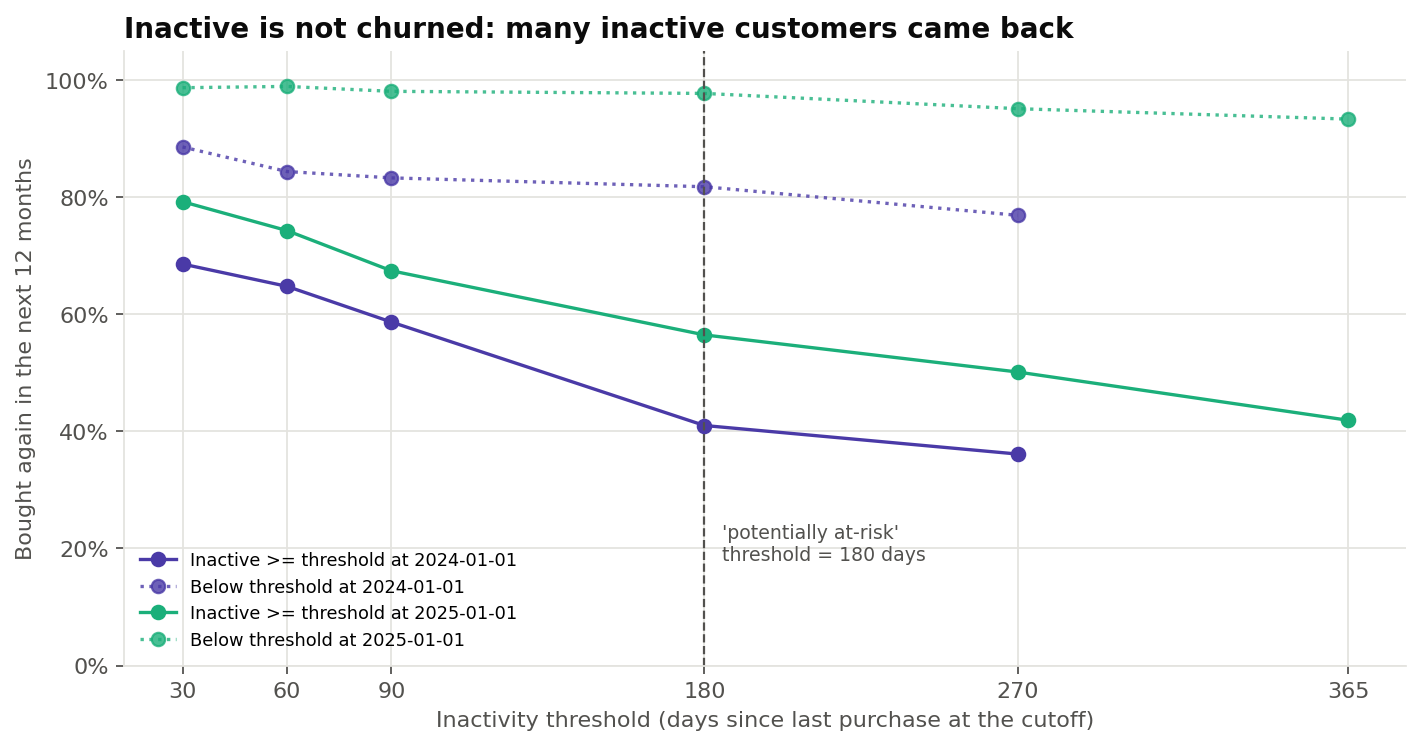

In [8]:
Image(str(FIG / "clv_inactivity_threshold.png"))

In [9]:
R['bgnbd']['evaluation']

,Item,Result
0,Calibration period,2023-01-01 to 2024-12-31
1,Hold-out period,2025-01-01 to 2025-12-31
2,Customers in calibration,"1,635"
3,"Fitted parameters (r, alpha, a, b)","1.866, 32.10, 0.0817, 0.854"
4,Optimiser converged,True
5,Hold-out orders: predicted vs actual,"4,022 vs 4,575 (87.9% of actual)"
6,Hold-out orders per customer: MAE,1.54
7,Hold-out orders per customer: R²,0.381
8,Hold-out orders: Spearman rank correlation,0.611
9,"Gamma-Gamma check: Pearson r(frequency, avg order value), repeat customers","0.225 (p = 1.2e-16, n = 1,321)"


**Decision, based on the evidence above:**
- **Supported:**
  - repeat purchasing (89% of customers have 2+ orders);
  - frequency;
  - 36 months of history, which allows a 12-month feature window followed by a 12-month target, twice.
- **Not observable: churn.**
  - Of customers inactive for 180+ days, 41% (2024 cutoff) and 56% (2025 cutoff) bought again within 12 months.
  - So inactivity is **not** churn. A 180-day threshold is used only to flag customers as *potentially at-risk*.
  - 180 days sits between the 75th (123 days) and 90th (232 days) percentiles of normal repeat gaps.
- **Not stationary:** active customers rose each year.
- **BG/NBD:** fitted with scipy and tested on 2025. It predicted 88% of hold-out orders (R² 0.38 on order counts), so it is kept as a **benchmark**.
- **Gamma-Gamma rejected:** spend per order and purchase frequency are correlated (Pearson 0.23, Spearman 0.39), which violates its key assumption.
- **Chosen method:**
  - a supervised model, trained on past behaviour to predict **next-12-month profit**;
  - validated **out-of-time** (2024 behaviour → 2025 profit);
  - compared against the simplified formula, a naive rule and BG/NBD.

## 6. Customer Value Calculation

In [10]:
print("Train panel :", len(R["train"]), "customers |", R["train"]["Feature_Window"].iloc[0], "->", R["train"]["Target_Window"].iloc[0])
print("Test panel  :", len(R["test"]), "customers |", R["test"]["Feature_Window"].iloc[0], "->", R["test"]["Target_Window"].iloc[0])
sp = R["estimates"]["scoring_panel"]
print("Scoring     :", len(sp), "customers |", sp["Feature_Window"].iloc[0], "-> next 12 months (not in the data)")
print("Max feature date (train/test):", R["train"].attrs["max_feature_date"].date(), "/", R["test"].attrs["max_feature_date"].date())

Train panel : 1137 customers | 2023-01-01 to 2023-12-31 -> 2024-01-01 to 2024-12-31
Test panel  : 1328 customers | 2024-01-01 to 2024-12-31 -> 2025-01-01 to 2025-12-31
Scoring     : 1716 customers | 2025-01-01 to 2025-12-31 -> next 12 months (not in the data)
Max feature date (train/test): 2023-12-31 / 2024-12-31


In [11]:
R['feature_selection']['table']

,Feature,VIF_All_Candidates,Decision,Reason,VIF_Final_Set,Spearman_with_Target_(train)
0,Recency_Days,2.212,Kept,value component (always kept),2.143,-0.330
1,Frequency,416.355,Kept,value component (always kept),3.516,0.361
2,Revenue,"1,590.403",Excluded,exact identity = AOV x Frequency,NaN,0.319
3,Profit,250.662,Excluded,exact identity = AOV x Frequency x Profit_Margin,NaN,0.341
4,Quantity,7.375,Excluded,VIF 7.3 > 5 (redundant with other features),NaN,0.339
5,AOV,824.892,Kept,value component (always kept),2.361,0.193
6,Avg_Profit_per_Order,226.258,Excluded,exact identity = AOV x Profit_Margin,NaN,0.207
7,Profit_Margin,4.868,Kept,value component (always kept),2.008,-0.062
8,Avg_Discount,3.705,Kept,VIF <= 5,2.384,-0.127
9,Categories,1.741,Kept,VIF <= 5,1.490,0.335


- **Feature period:** the 12 months before a cutoff. **Target:** Delivered profit in the 12 months after it. No feature uses any transaction on or after the cutoff.
- **Not used as features:** RFM segments and cluster labels, because they were computed on the full 2023–2025 period.
- **Features dropped as exact identities** (they would make the linear model unstable):
  - Revenue = AOV × Frequency;
  - Profit = AOV × Frequency × Margin;
  - Profit per order = AOV × Margin.
- **Features dropped for redundancy:** Quantity and Purchase_Rate (VIF above 5).
- **Result:** the 8 remaining features all have VIF ≤ 3.5.

In [12]:
R['estimates']['scores'].head()

,Customer_ID,Estimated_12M_Future_Profit,Simplified_12M_Estimate,Estimate_Method,Illustrative_3Y_Value
0,CUST-0001,"4,633.736","2,817.685",ML model (active in last 12 months),"11,787.579"
1,CUST-0002,"5,787.615","6,080.497",ML model (active in last 12 months),"14,722.886"
2,CUST-0003,"3,531.557","1,027.190",ML model (active in last 12 months),"8,983.789"
3,CUST-0004,"1,174.389",109.320,ML model (active in last 12 months),"2,987.483"
4,CUST-0005,"7,254.439","4,988.317",ML model (active in last 12 months),"18,454.283"


In [13]:
e = R["estimates"]
print("Customers scored by the model:", int((c["Estimate_Method"].str.startswith("ML")).sum()))
print("Customers with no order in 2025 (group estimate):", int((~c["Estimate_Method"].str.startswith("ML")).sum()),
      "| group value:", clv.inr(e["lapsed_value"]), f"| {e['lapsed_repeat']:.0%} of the equivalent 2025 group bought again")
print("Illustrative 3-year factor (1 + r + r^2), r =", round(e["repeat_rate"], 3), "->", round(e["horizon_factor"], 3))
e["horizon_sensitivity"]

Customers scored by the model: 1716
Customers with no order in 2025 (group estimate): 268 | group value: ₹830 | 41% of the equivalent 2025 group bought again
Illustrative 3-year factor (1 + r + r^2), r = 0.839 -> 2.544


,Scenario,Annual_Repeat_Rate,Horizon_Factor,Total_Illustrative_3Y_Value
0,2023->2024 observed,0.730,2.263,"16,739,251.864"
1,Pooled observed (used),0.839,2.544,"18,817,771.402"
2,2024->2025 observed,0.933,2.803,"20,737,942.526"


## 7. CLV Distribution Analysis

In [14]:
R['distribution']['summary']

,Measure,Customers,Total,Mean,Median,Std,Min,Max,Mean_to_Median,Skewness,Skewness_log1p,Customers_below_zero
0,Historical revenue,1984,"60,056,569.150","30,270.448","13,513.325","43,789.879",237.750,"417,800.450",2.240,3.207,-0.069,0
1,Historical profit,1984,"14,022,551.580","7,067.818","3,893.300","8,863.116","-5,257.690","67,797.590",1.815,2.606,-2.301,32


In [15]:
R['distribution']['percentiles']

,Percentile,Historical_Revenue,Historical_Profit,Total_Orders,Customer_Tenure_Days
0,P1,648.338,-609.181,1.000,27.000
1,P5,"1,649.200",450.082,1.000,84.000
2,P10,"2,631.800",791.941,1.000,152.300
3,P25,"5,790.350","1,755.022",3.000,457.000
4,P50,"13,513.325","3,893.300",4.000,788.000
5,P75,"35,786.838","8,923.050",8.000,967.250
6,P90,"75,003.035","16,106.946",12.000,"1,058.000"
7,P95,"117,847.835","28,164.656",19.000,"1,078.000"
8,P99,"228,972.167","43,000.995",27.000,"1,093.000"


In [16]:
R['distribution']['concentration']

,Top_Customers_%,Customers,Revenue_Share_%,Profit_Share_%
0,1.000,20,9.046,7.120
1,5.000,99,29.852,26.432
2,10.000,198,45.388,40.983
3,20.000,397,64.333,59.253
4,50.000,992,89.956,87.484


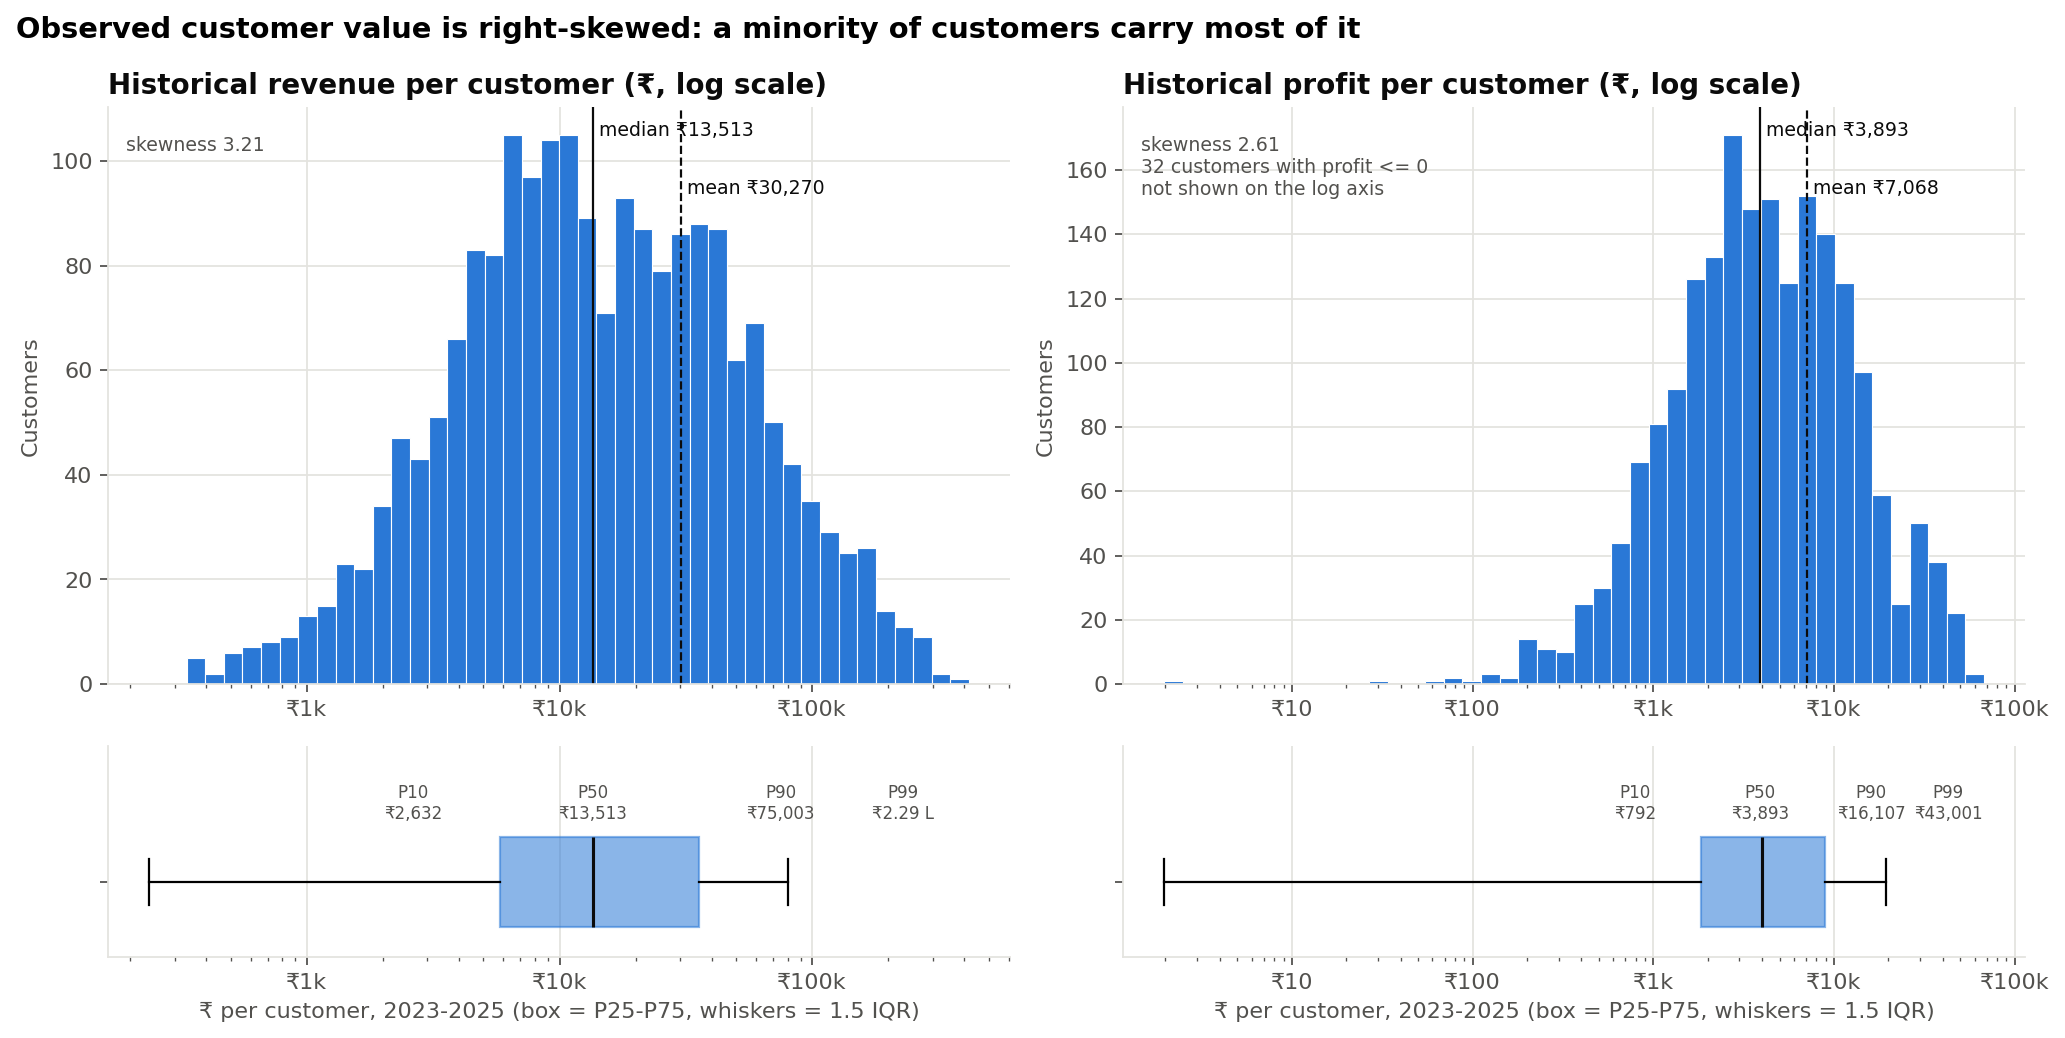

In [17]:
Image(str(FIG / "clv_distribution.png"))

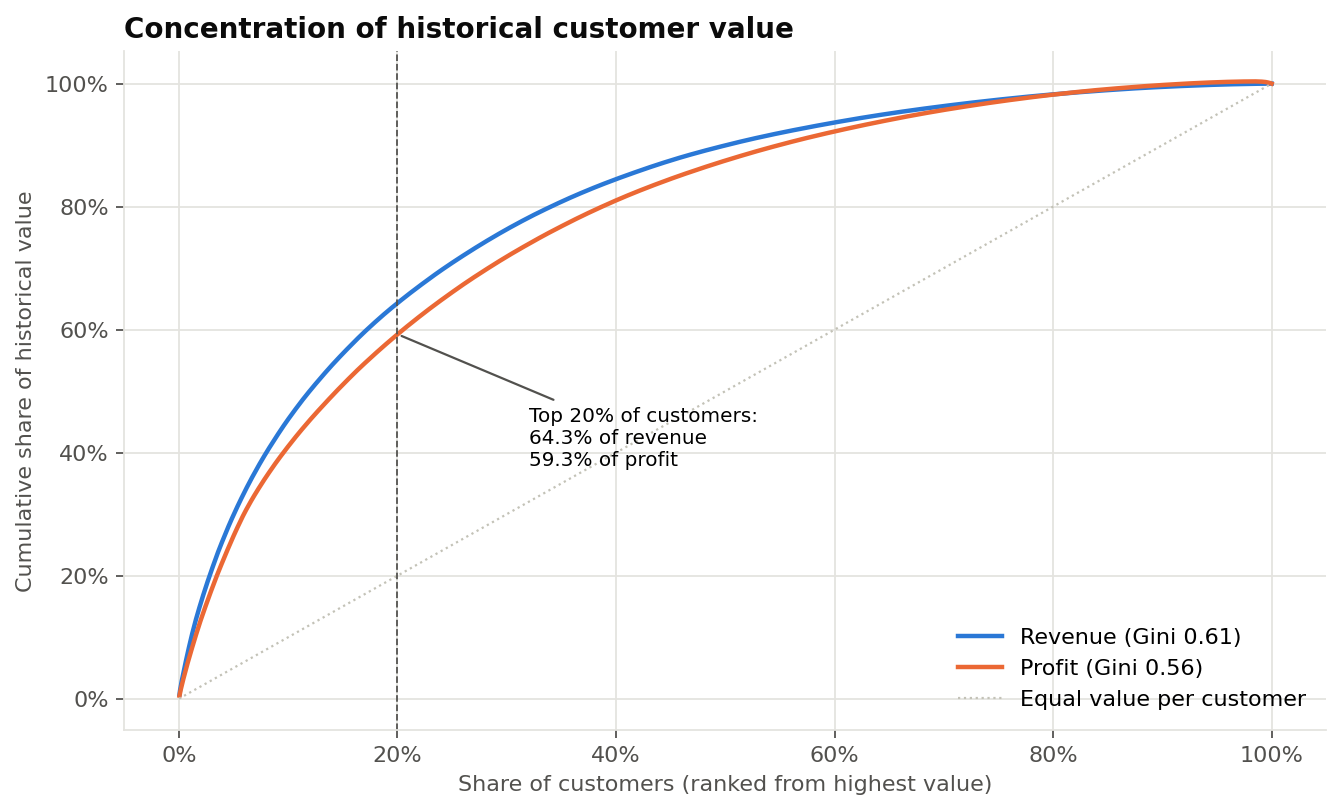

In [18]:
Image(str(FIG / "clv_value_concentration.png"))

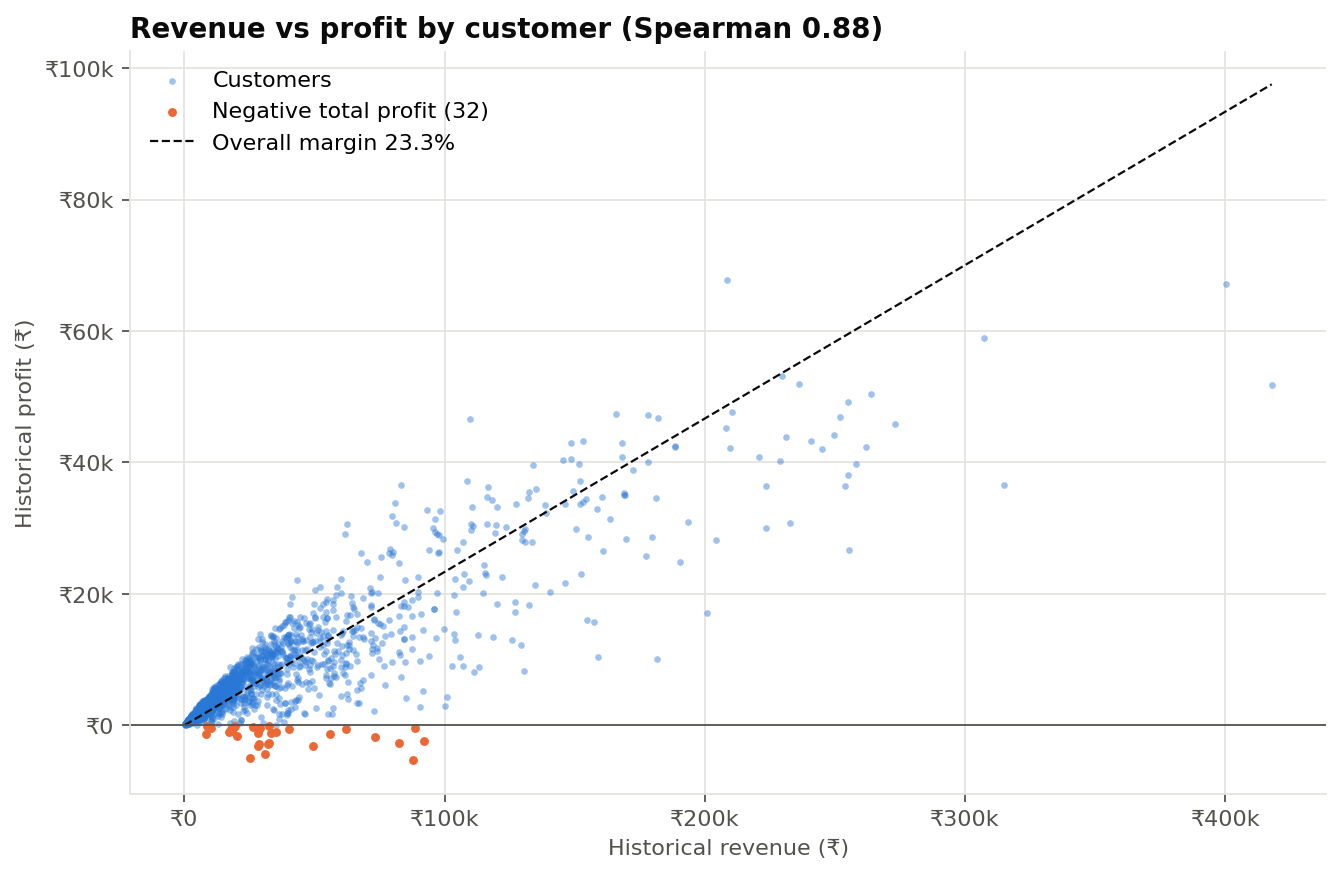

In [19]:
Image(str(FIG / "clv_revenue_vs_profit.png"))

- **Value is right-skewed.** Profit skewness is 2.61 and the mean is 1.82× the median (₹7,068 vs ₹3,893).
- **Concentration:** the top 20% of customers generated 59.3% of profit and 64.3% of revenue (Gini 0.56 and 0.61).
- **Revenue and profit move together** (Spearman 0.88), but 32 customers have negative total profit.

## 8. CLV by RFM Segment

In [20]:
R['by_rfm'][['RFM_Segment', 'Customer_Count', 'Avg_Historical_Revenue', 'Avg_Historical_Profit_CLV',
            'Total_Historical_Profit_CLV', 'Avg_Estimated_12M_Value', 'Total_Estimated_12M_Value',
            'Est_12M_to_Historical_Annual_Rate', 'Avg_AOV', 'Avg_Frequency', 'Avg_Recency_Days']]

,RFM_Segment,Customer_Count,Avg_Historical_Revenue,Avg_Historical_Profit_CLV,Total_Historical_Profit_CLV,Avg_Estimated_12M_Value,Total_Estimated_12M_Value,Est_12M_to_Historical_Annual_Rate,Avg_AOV,Avg_Frequency,Avg_Recency_Days
0,Champions,334,"96,796.678","21,316.197","7,119,609.820","8,441.507","2,819,463.390",0.976,"6,102.919",15.425,32.590
1,Loyal Customers,240,"35,745.407","8,400.841","2,016,201.850","4,549.544","1,091,890.538",1.054,"5,559.738",7.183,91.188
2,Potential Loyalists,152,"14,417.654","3,655.314","555,607.710","3,365.220","511,513.456",1.476,"4,400.692",4.197,46.632
3,Recent Customers,91,"5,368.820","1,863.493","169,577.850","3,068.770","279,258.093",1.795,"2,752.517",2.231,17.791
4,Promising,110,"5,117.343","1,760.510","193,656.100","2,355.812","259,139.345",1.596,"2,510.870",2.200,59.382
5,Needs Attention,123,"12,633.097","3,703.599","455,542.730","3,117.276","383,425.002",1.346,"3,210.203",4.472,120.650
6,About to Sleep,143,"4,232.603","1,295.283","185,225.470","2,015.881","288,270.940",2.030,"2,249.904",2.119,115.357
7,Can't Lose Them,79,"54,244.447","11,046.295","872,657.280","3,871.051","305,813.005",0.715,"5,882.110",9.797,228.291
8,At Risk,263,"25,716.705","6,157.359","1,619,385.490","3,113.858","818,944.716",0.934,"5,202.169",5.901,259.316
9,Hibernating,148,"6,593.431","2,269.532","335,890.750","2,291.531","339,146.621",1.605,"2,414.021",3.068,199.007


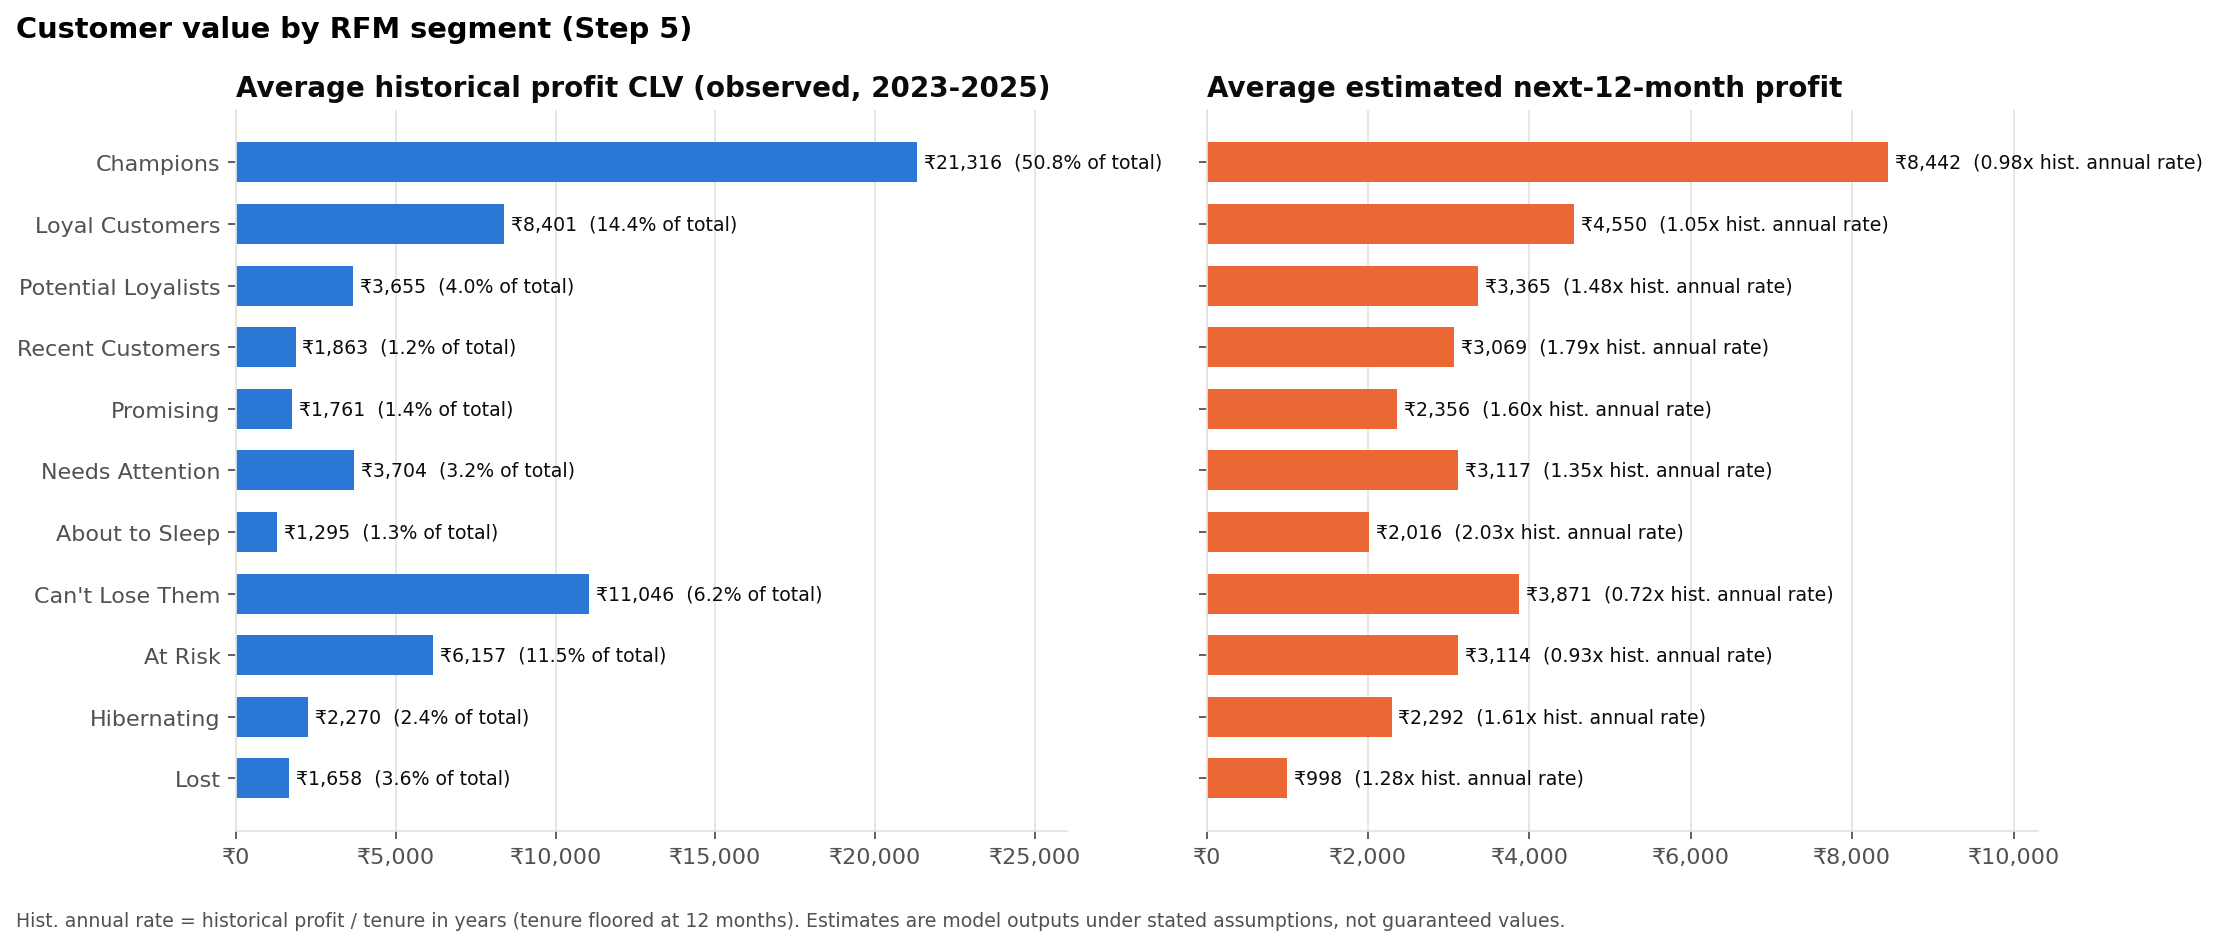

In [21]:
Image(str(FIG / "clv_by_rfm_segment.png"))

- **Champions:** highest historical and estimated value. The estimate (₹8,442) is close to their historical annual profit rate (₹8,650).
- **Can't Lose Them:** the lowest estimated-to-historical ratio (0.72×). The model expects this group to contribute less next year than its past pace.
- **Low-value, newer segments** (About to Sleep, Recent Customers, Promising): ratios above 1. This is partly real (short histories) and partly the model pulling estimates toward the average.

## 9. CLV by ML Cluster

In [22]:
R['by_cluster'][['Cluster_ID', 'Cluster_Label', 'Customer_Count', 'Avg_Historical_Revenue', 'Avg_Historical_Profit_CLV',
                'Total_Historical_Profit_CLV', 'Avg_Estimated_12M_Value', 'Total_Estimated_12M_Value',
                'Estimated_12M_Value_Share_%', 'Avg_AOV', 'Avg_Frequency', 'Avg_Recency_Days']]

,Cluster_ID,Cluster_Label,Customer_Count,Avg_Historical_Revenue,Avg_Historical_Profit_CLV,Total_Historical_Profit_CLV,Avg_Estimated_12M_Value,Total_Estimated_12M_Value,Estimated_12M_Value_Share_%,Avg_AOV,Avg_Frequency,Avg_Recency_Days
0,0,"High-Value, Active",364,"91,851.284","20,359.811","7,410,971.150","8,127.741","2,958,497.842",39.994,"5,915.537",14.882,31.695
1,1,"Low-Value, Active",453,"6,658.440","2,107.012","954,476.260","2,621.443","1,187,513.757",16.053,"2,637.469",2.751,63.857
2,2,"Mid-Value, Lapsing",753,"28,228.762","6,623.733","4,987,670.740","3,620.988","2,726,604.006",36.859,"4,966.008",6.238,172.992
3,3,"Low-Value, Inactive",414,"5,676.740","1,616.989","669,433.430","1,267.420","524,711.679",7.093,"3,073.164",2.058,590.587


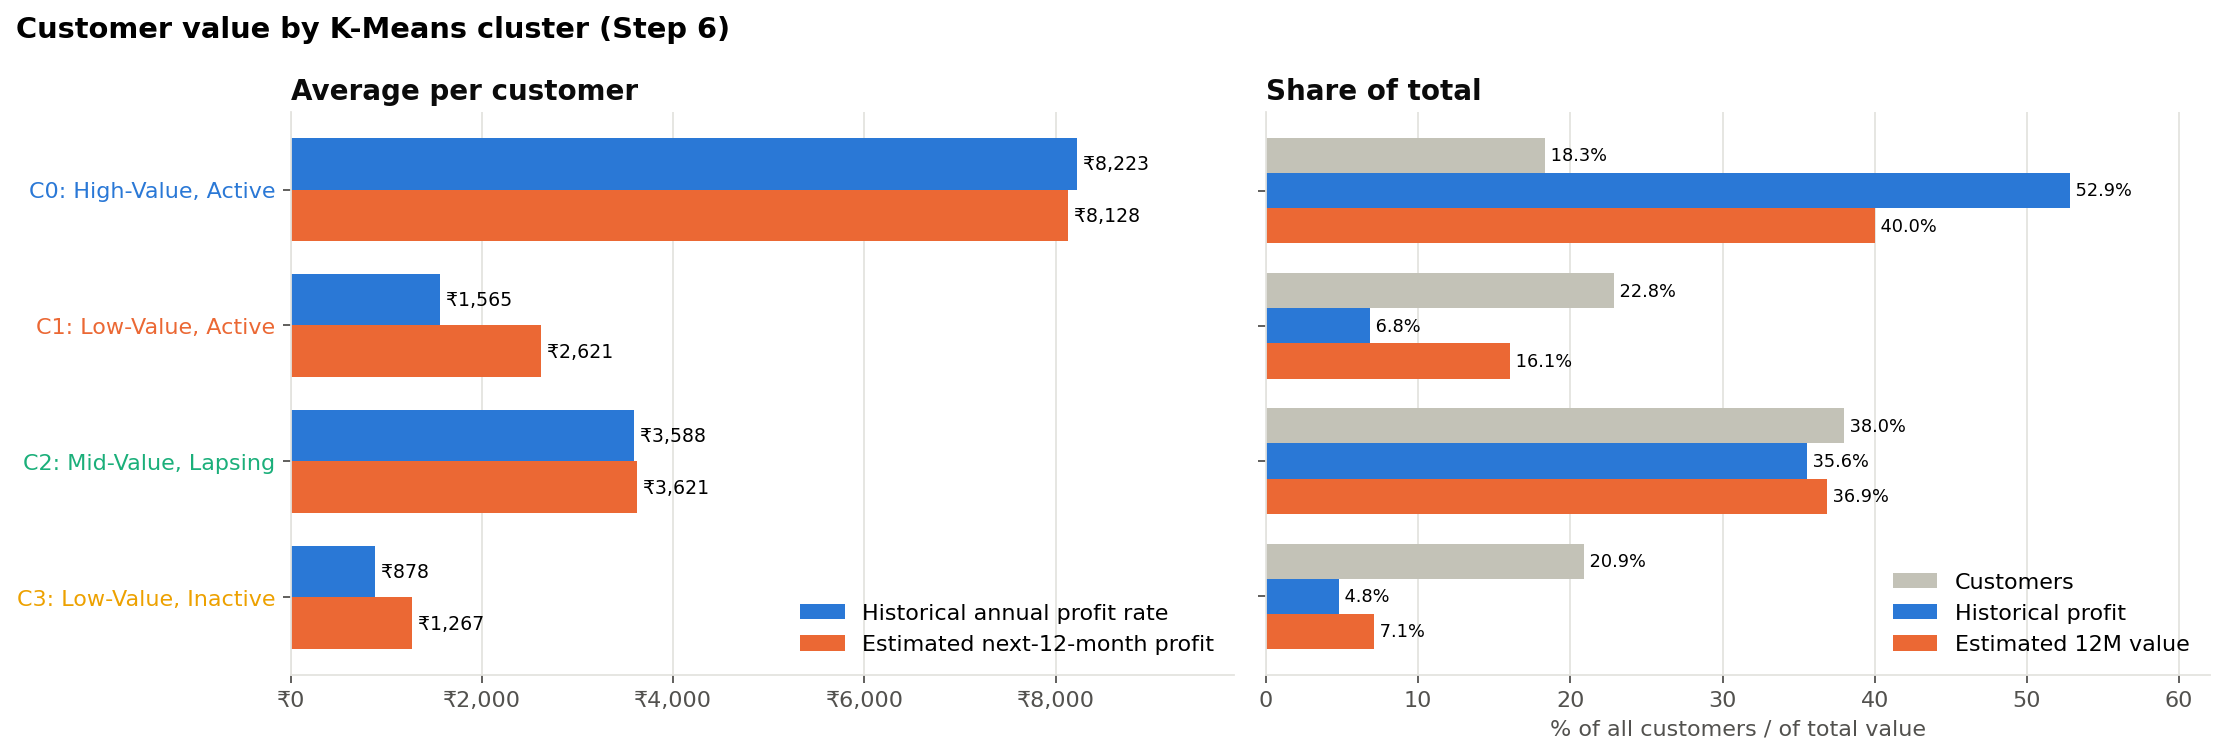

In [23]:
Image(str(FIG / "clv_by_ml_cluster.png"))

- **Cluster 0 (High-Value, Active):** 18.3% of customers, 52.9% of historical profit and 40.0% of estimated 12-month value. It has the highest value per customer.
- **Cluster 2 (Mid-Value, Lapsing):** 36.9% of estimated value, driven by its size (753 customers).
- **Clusters 0 and 2 together:** 76.9% of estimated value.

## 10. Customer Value Drivers

In [24]:
R['drivers']['decomposition']

,Component,Share_of_log_Profit_Variance_%
0,Number of orders,61.964
1,Average order value,39.268
2,Profit margin,-1.231


In [25]:
R['drivers']['historical']

,Characteristic,Spearman_with_Historical_Profit,p_value
0,Number of orders,0.873,0.000
1,Average order value,0.585,0.000
2,Categories bought,0.776,0.000
3,Tenure (days),0.363,0.000
4,Recency (days since last purchase),-0.364,0.000
5,Average discount,-0.392,0.000
6,Return/cancel rate,0.139,0.000
7,Profit margin,-0.186,0.000


In [26]:
R['drivers']['future']

,Feature_at_Cutoff,Spearman_with_Future_12M_Profit,p_value
3,Profit,0.440,0.000
1,Frequency,0.433,0.000
2,Revenue,0.431,0.000
9,Categories,0.413,0.000
4,Quantity,0.406,0.000
11,Purchase_Rate,0.348,0.000
5,AOV,0.313,0.000
6,Avg_Profit_per_Order,0.301,0.000
0,Recency_Days,-0.288,0.000
8,Avg_Discount,-0.222,0.000


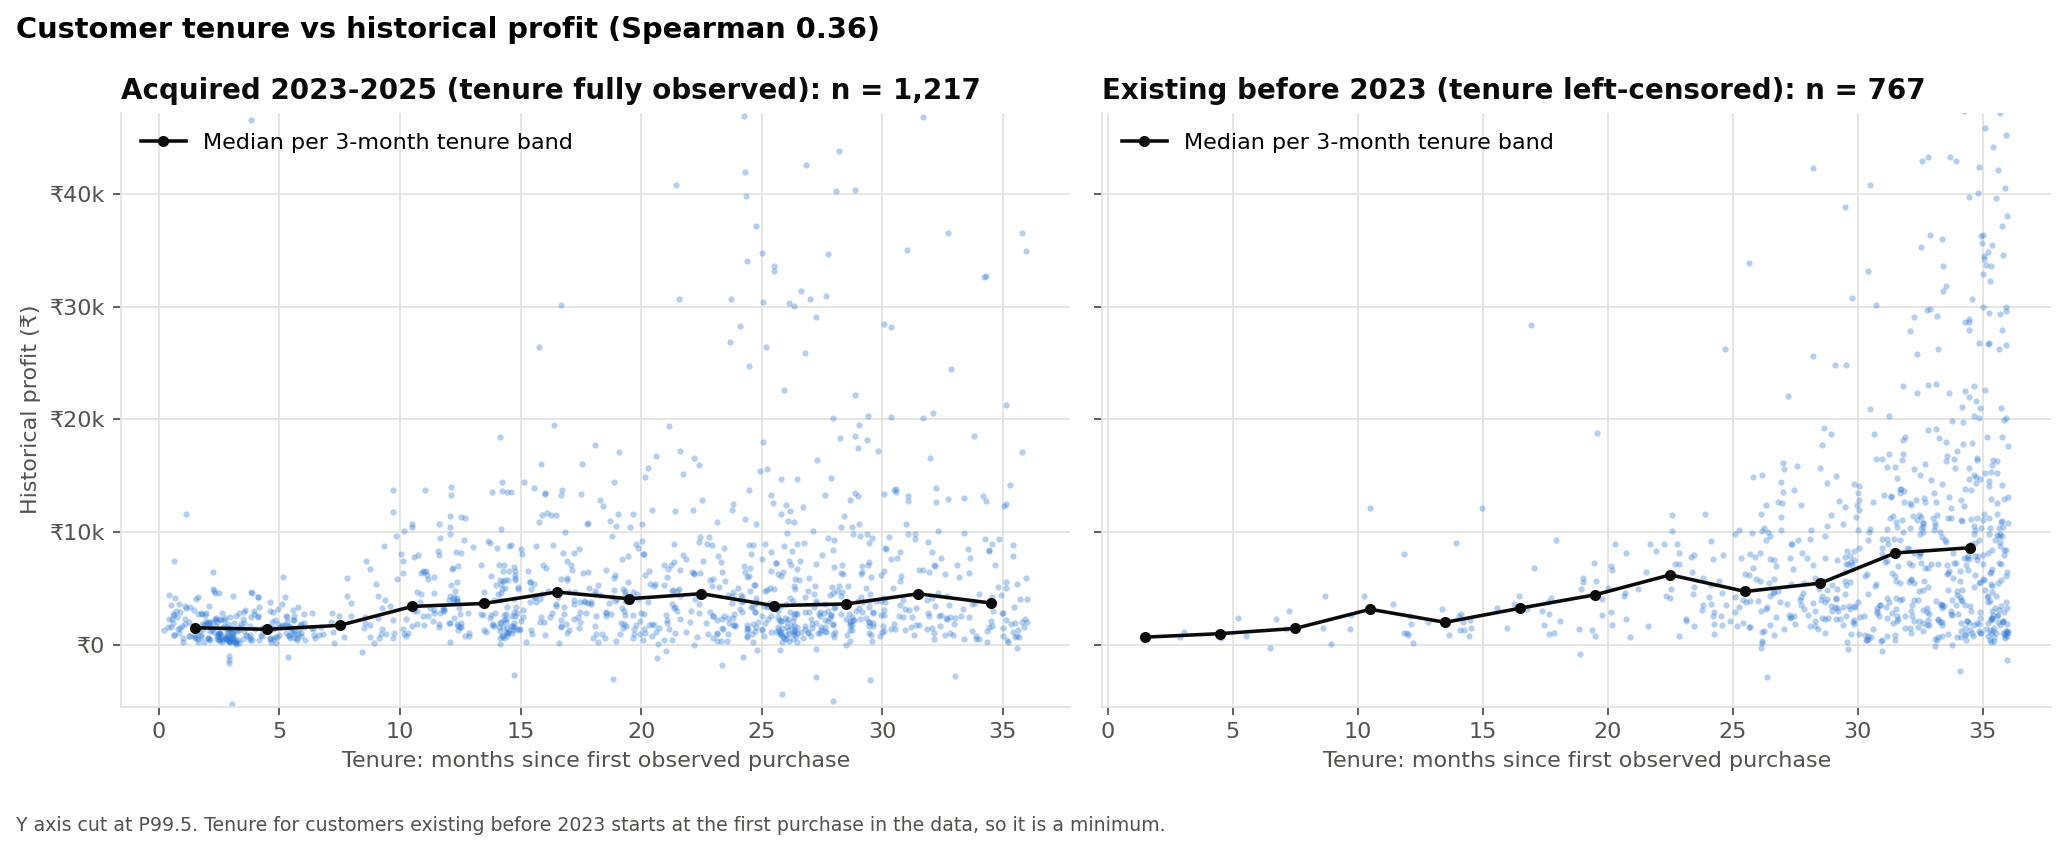

In [27]:
Image(str(FIG / "customer_tenure_vs_value.png"))

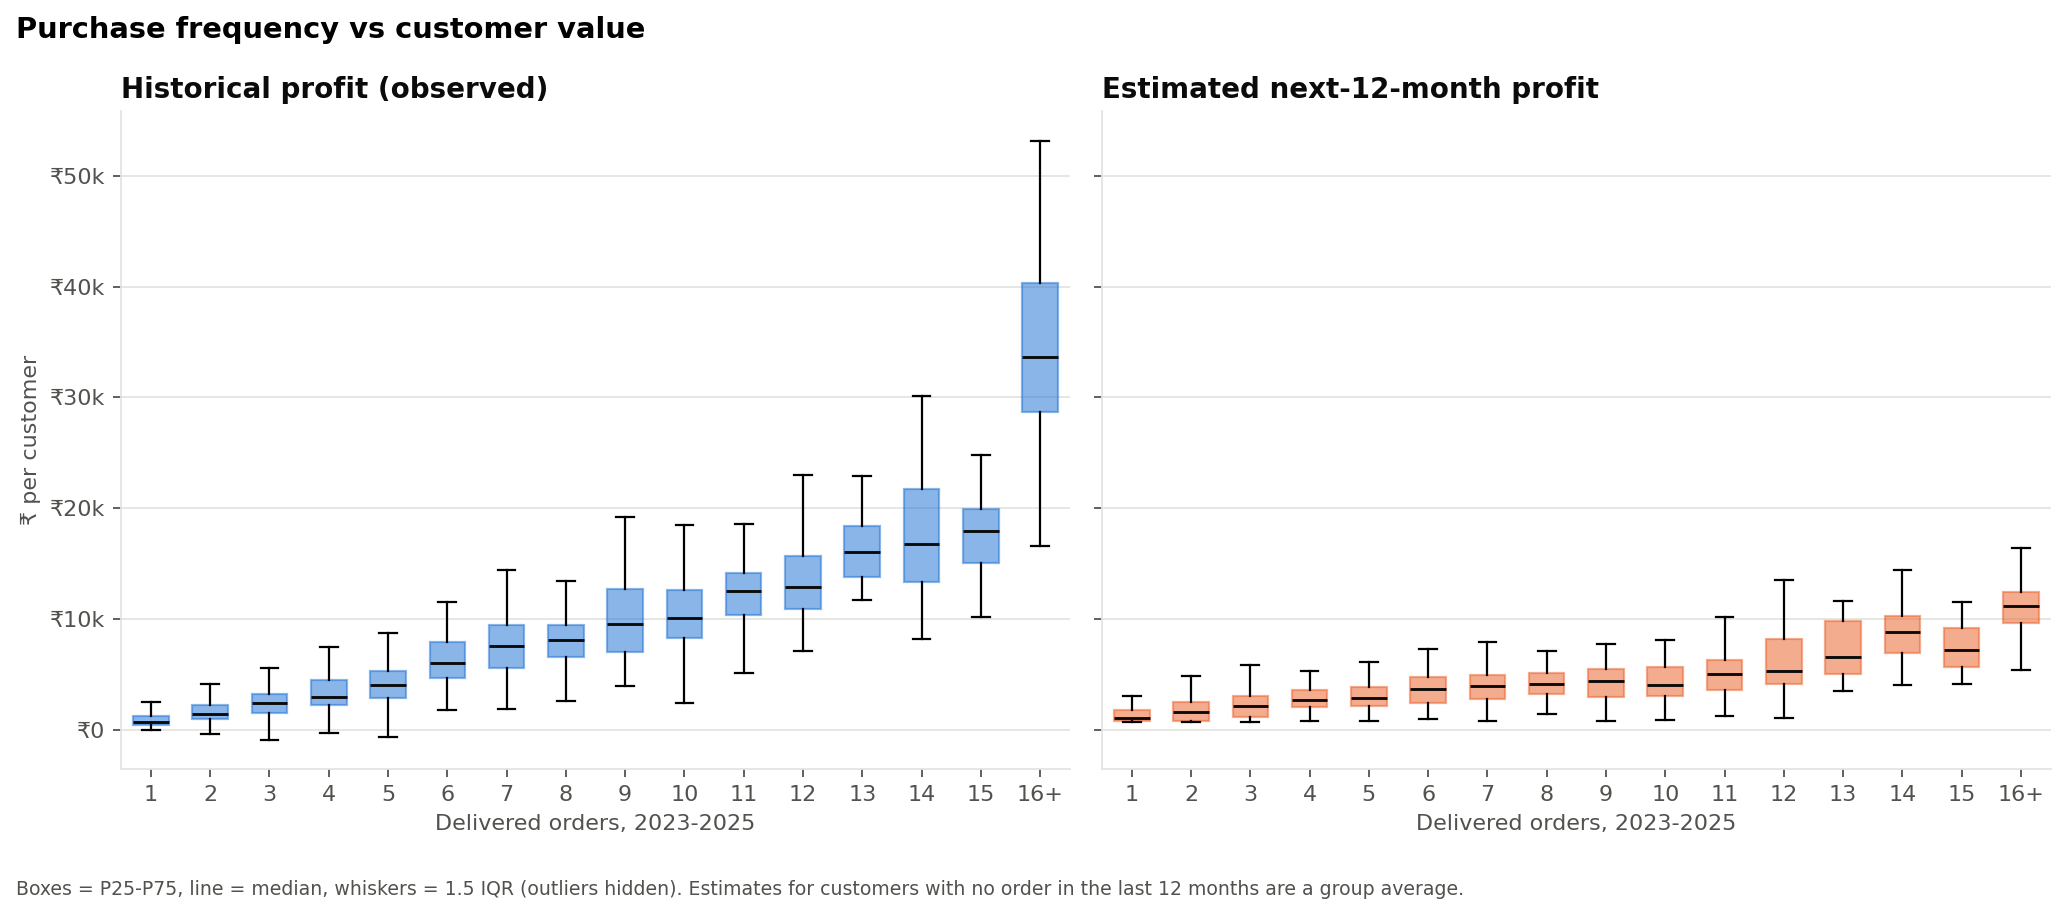

In [28]:
Image(str(FIG / "frequency_vs_clv.png"))

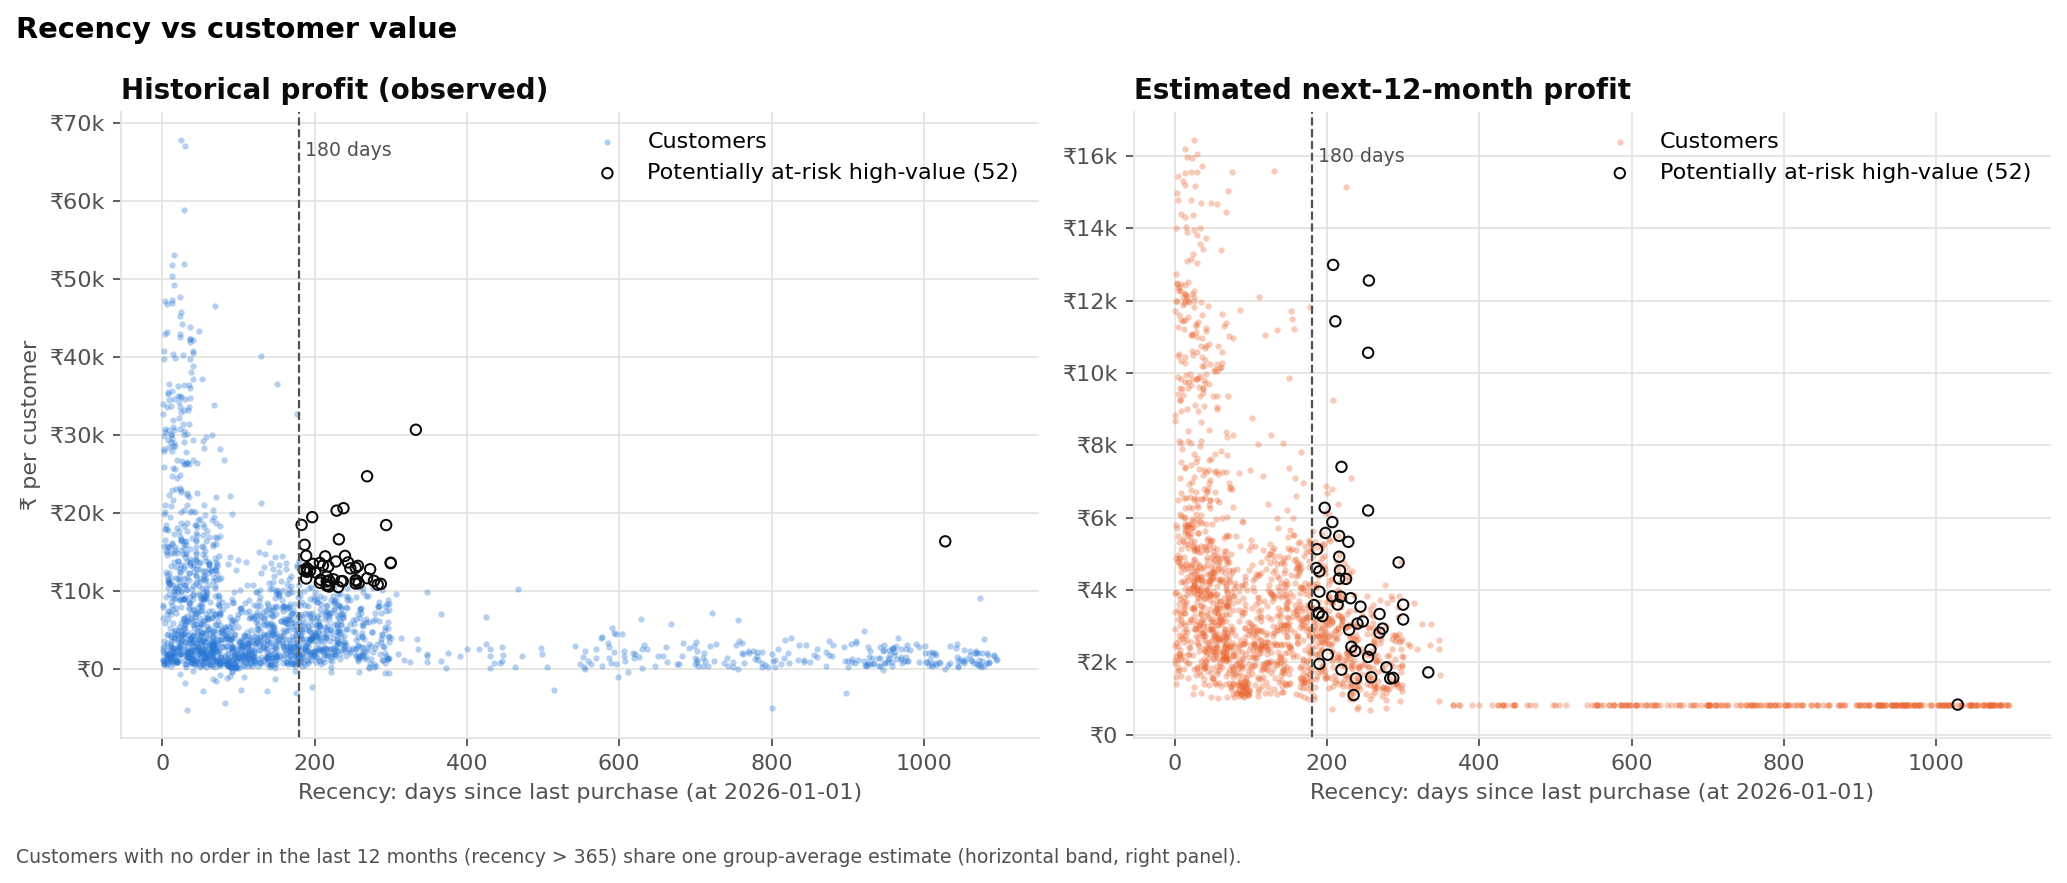

In [29]:
Image(str(FIG / "recency_vs_clv.png"))

- **Historical profit = orders × AOV × margin.** The number of orders explains about 62% of the variance in log profit and AOV about 39%. Margins differ little between customers.
- **Future profit:** last-12-month profit, frequency, revenue and category breadth have the strongest rank correlations with next-year profit (Spearman 0.41–0.44). Recency is negatively correlated (−0.29), and so is average discount (−0.22).
- **Tenure:** correlates with historical profit (Spearman 0.36), but part of that is simply more time to buy.
- **All of these are associations, not causes.**

## 11. CLV Estimation / Prediction

In [30]:
R['trained']['cv']

,Model,CV_RMSE,CV_RMSE_Std,CV_MAE,CV_R2,Selected
0,Ridge regression (baseline),"3,792.505",340.612,"2,537.748",0.191,False
1,Random forest,"3,696.678",254.266,"2,414.040",0.224,True
2,Gradient boosting,"3,765.612",270.330,"2,450.523",0.190,False


In [31]:
comp = R["evaluation"]["comparison"]
comp[["Model", "Type", "MAE", "RMSE", "R2", "WAPE_%", "MAPE_nonzero_%", "Spearman", "Top20_Capture_%", "Predicted_to_Actual_Total", "Selected"]]

,Model,Type,MAE,RMSE,R2,WAPE_%,MAPE_nonzero_%,Spearman,Top20_Capture_%,Predicted_to_Actual_Total,Selected
0,Ridge regression (baseline),ML model,"2,852.844","4,468.807",0.201,69.538,167.161,0.478,41.690,0.802,False
1,Random forest,ML model,"2,793.356","4,269.361",0.270,68.088,175.600,0.487,41.455,0.899,True
2,Gradient boosting,ML model,"2,982.016","4,323.155",0.252,72.686,208.448,0.496,43.046,1.086,False
3,Naive: last-12-month profit repeats,Benchmark,"2,946.638","4,647.835",0.135,71.824,147.228,0.440,41.129,0.852,False
4,Simplified formula (AOV x F x margin x P(repeat)),Benchmark,"2,859.271","4,606.126",0.151,69.694,123.319,0.464,40.748,0.677,False
5,BG/NBD orders x avg profit per order,Benchmark,"2,693.408","4,356.134",0.241,65.651,137.308,0.490,41.701,0.754,False


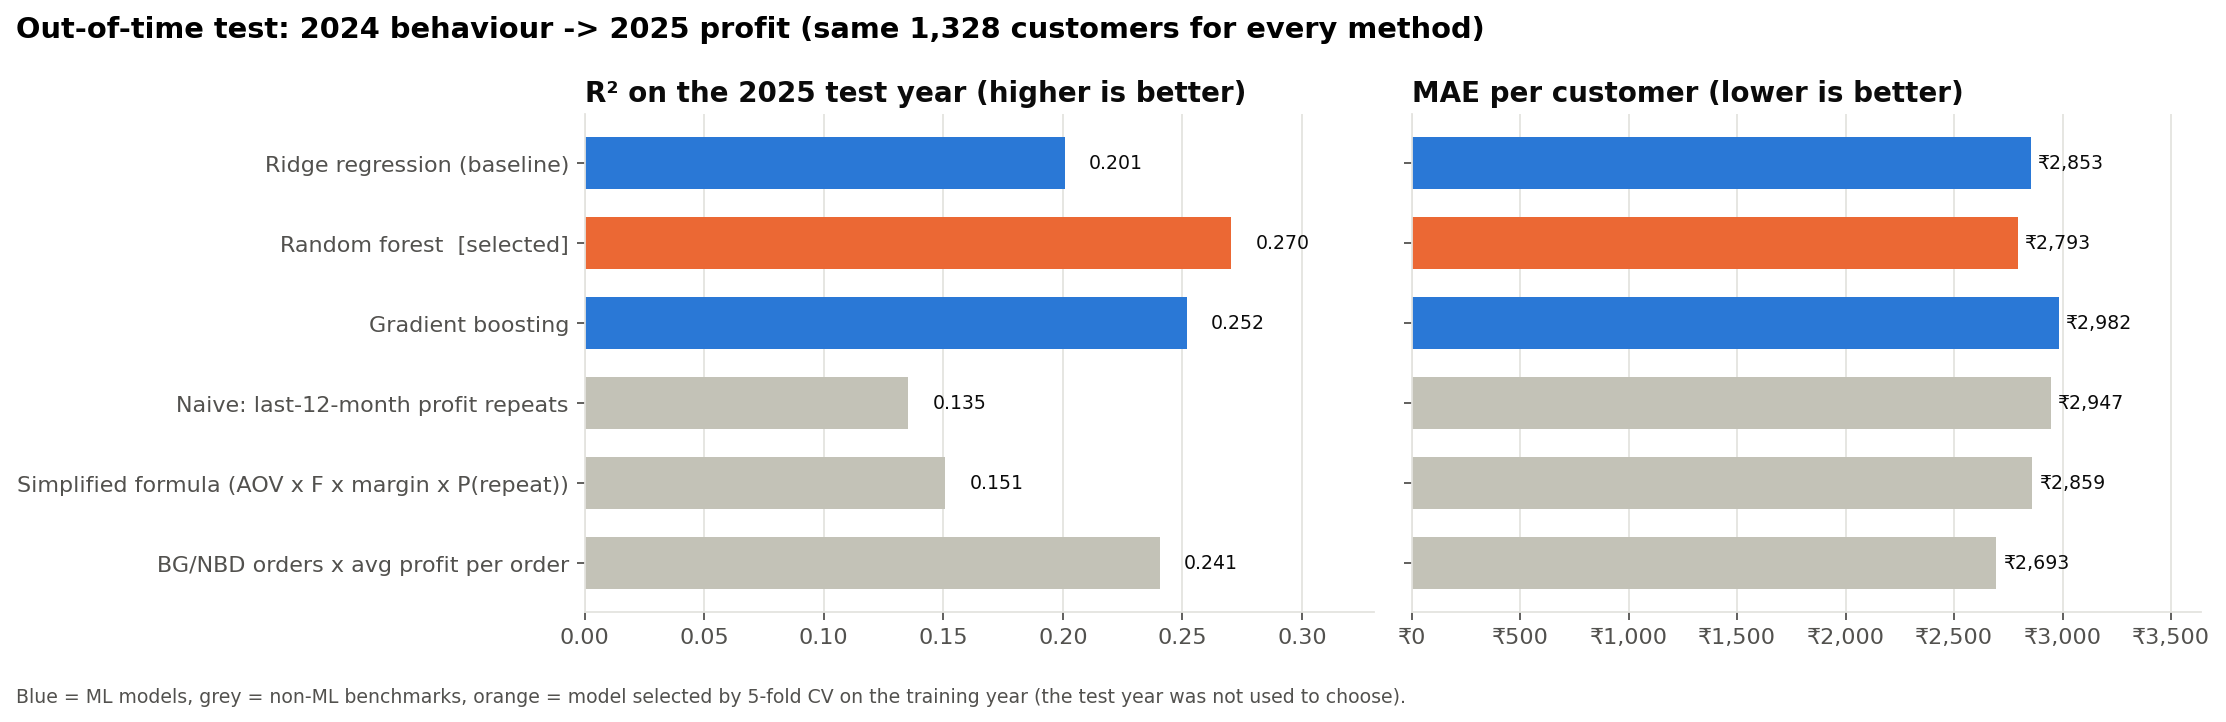

In [32]:
Image(str(FIG / "clv_model_comparison.png"))

- **Candidates:** an interpretable **Ridge** baseline, plus Random Forest and Gradient Boosting.
- **Selection rule:** lowest 5-fold CV RMSE on the **training** year only. The Random Forest won (3,697 vs 3,793 for Ridge).
- **Final fit:** the same specification was refit on the 2024 and 2025 targets together to score customers at 2026-01-01.
- **Benchmarks on the same 1,328 test customers:**
  - the naive "last year repeats" rule;
  - the simplified formula (AOV × F × margin × P(repeat));
  - BG/NBD × average profit per order.
- **Result:** the benchmarks are competitive. BG/NBD has the lowest MAE, and the Random Forest has the highest R² and lowest RMSE.

## 12. Model Validation

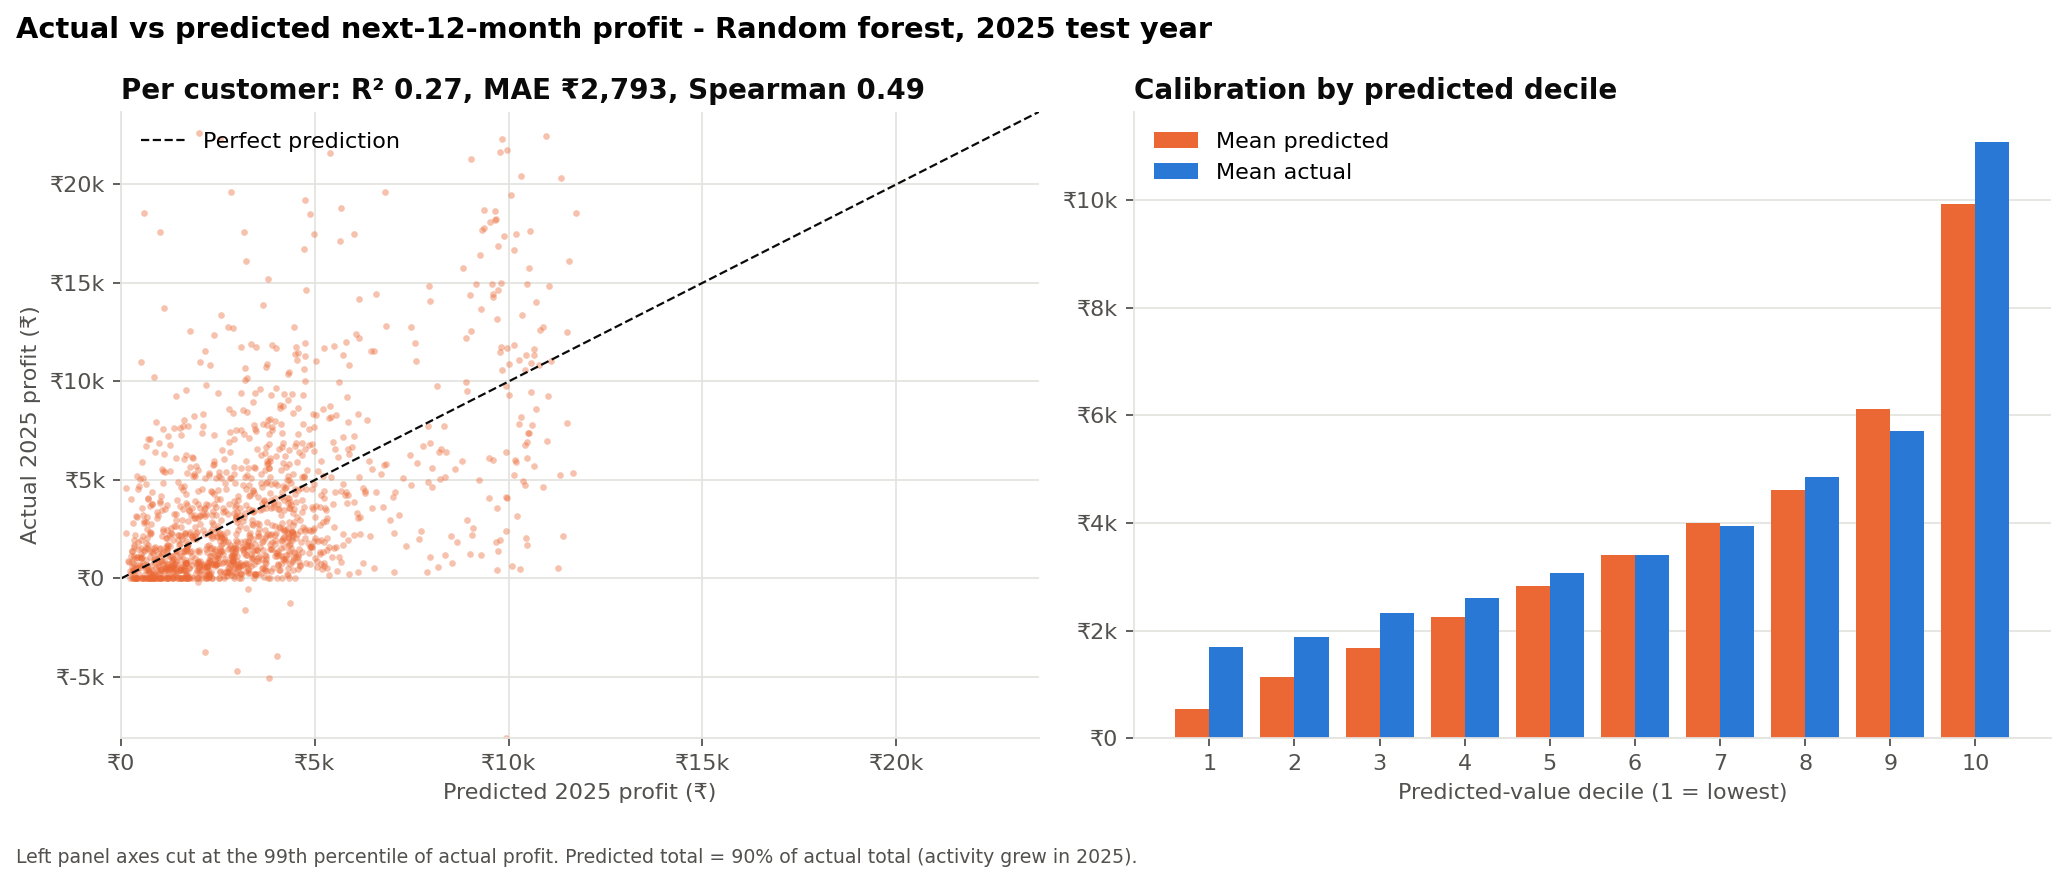

In [33]:
Image(str(FIG / "clv_actual_vs_predicted.png"))

In [34]:
R['evaluation']['calibration']

,Predicted_Decile,Customers,Mean_Predicted,Mean_Actual,Share_Purchased
0,1,133,539.790,"1,703.055",0.774
1,2,133,"1,129.830","1,883.745",0.842
2,3,133,"1,678.189","2,325.586",0.865
3,4,132,"2,254.783","2,596.669",0.932
4,5,133,"2,826.234","3,062.801",0.970
5,6,133,"3,397.038","3,403.924",0.992
6,7,132,"4,004.766","3,940.988",0.970
7,8,133,"4,615.718","4,858.089",0.985
8,9,133,"6,120.476","5,709.683",1.000
9,10,133,"9,924.698","11,090.359",1.000


In [35]:
R['importance']

,Feature,Permutation_MAE_Increase,Permutation_Std,Ridge_Std_Coefficient,Transform
0,Frequency,628.455,41.182,"1,148.871",arcsinh + scale
1,Avg_Discount,99.511,17.438,-276.594,scale
2,Recency_Days,97.438,16.435,-565.401,arcsinh + scale
3,AOV,42.673,9.610,453.115,arcsinh + scale
4,Tenure_Days_Capped,14.858,6.371,-220.701,scale
5,Categories,3.856,4.621,377.319,scale
6,Return_Rate,0.967,3.055,187.743,scale
7,Profit_Margin,-1.151,8.856,333.753,scale


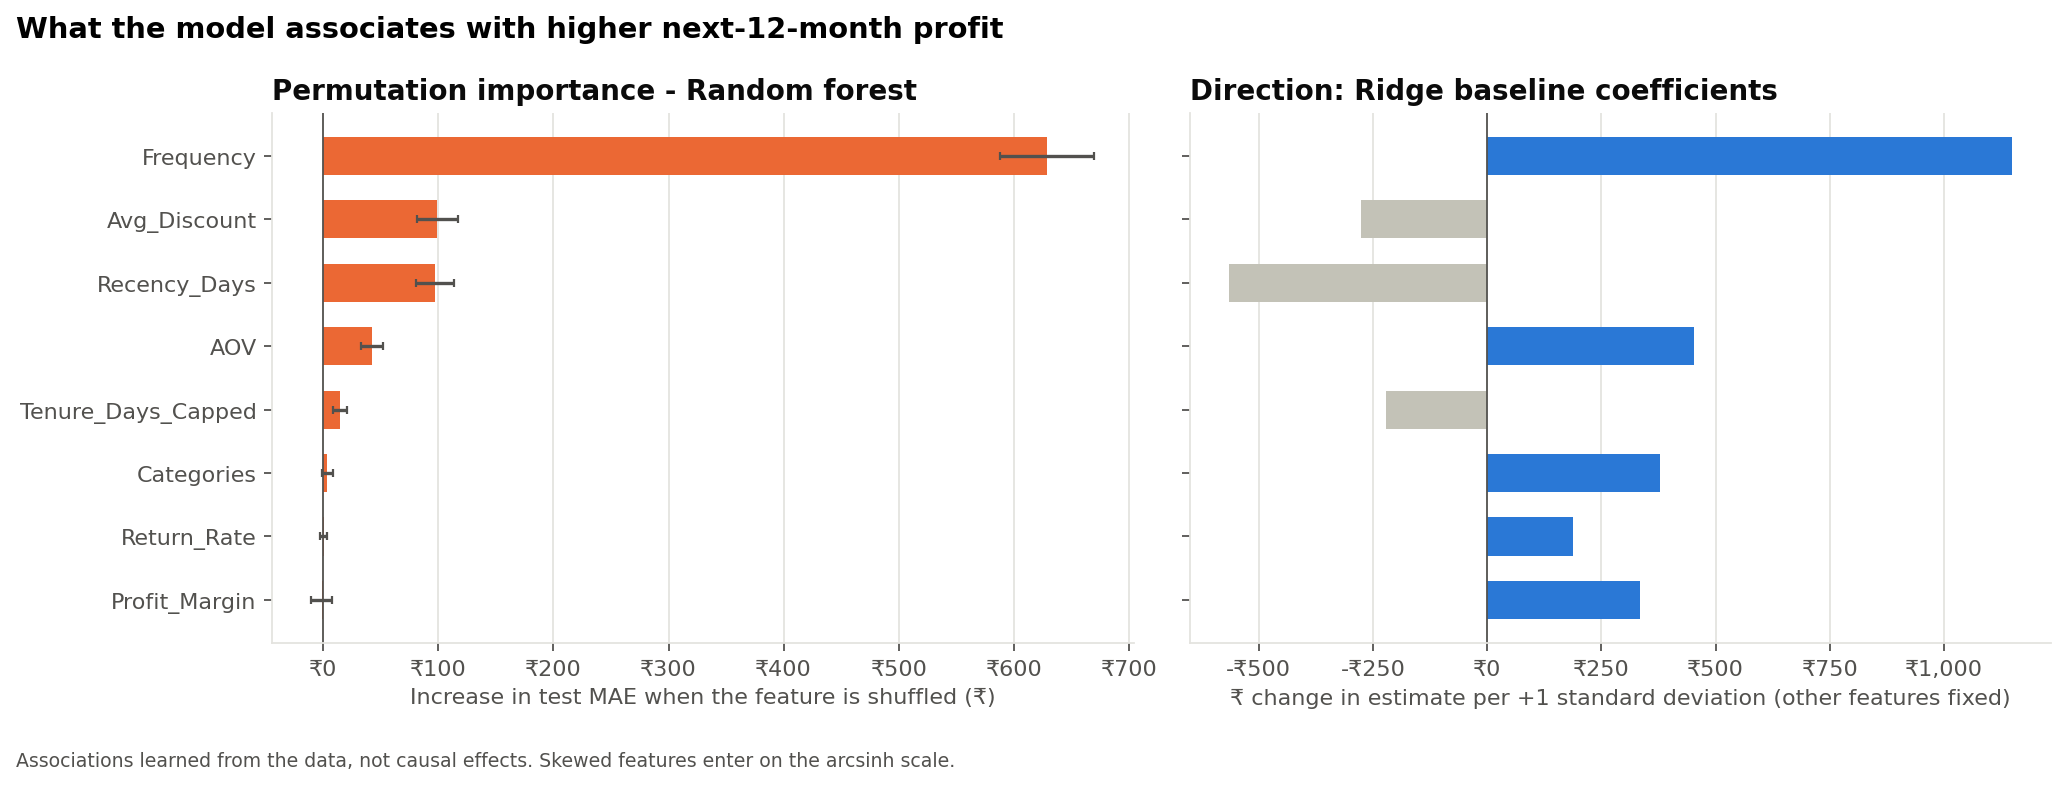

In [36]:
Image(str(FIG / "clv_feature_importance.png"))

In [37]:
R['validation']

,Check,Value,Pass
0,One row per customer (no duplicate IDs),0,True
1,Customers = valid population (>= 1 Delivered order) = Step 5 RFM,"1,984 vs 1,984 vs 1,984",True
2,Revenue reconciles with cleaned Delivered sales,₹6.01 Cr vs ₹6.01 Cr,True
3,Profit reconciles with cleaned Delivered profit,₹1.40 Cr vs ₹1.40 Cr,True
4,Revenue - cost = profit for every customer,all customers,True
5,Orders and revenue match Step 5 Frequency / Monetary,per customer,True
6,Tenure non-negative; first <= last <= reference date,min tenure 7 d,True
7,No leakage: every feature date < cutoff (train & test),"train max 2023-12-31, test max 2024-12-31",True
8,Time integrity: target dates >= cutoff; training target window ends before test target window,"train target from 2024-01-01, test target from 2025-01-01",True
9,"No leakage: no target, RFM/cluster label or ID among model features","Recency_Days, Frequency, AOV, ...",True


In [38]:
# Independent check: reload the saved artefacts from disk and re-score
pre = joblib.load(ROOT / "models" / "clv_preprocessor.pkl")
model = joblib.load(ROOT / "models" / "clv_model.pkl")
X = R["estimates"]["scoring_panel"][clv.MODEL_FEATURES]
reloaded = np.clip(model.predict(pre.transform(X)), 0, None)
saved = c.set_index("Customer_ID").loc[R["estimates"]["scoring_panel"]["Customer_ID"], "Estimated_12M_Future_Profit"]
print("Reloaded model reproduces saved estimates:", np.allclose(reloaded, saved.to_numpy(), atol=0.01))

Reloaded model reproduces saved estimates: True


- **Out-of-time test (2024 → 2025):** R² 0.27, MAE ₹2,793, RMSE ₹4,269, Spearman 0.49. The top 20% of predicted customers captured 41.5% of actual 2025 profit.
- **MAPE:** not a headline metric, because 6.7% of test customers had zero future profit.
- **Bias:** predicted total = 90% of actual. 2025 activity grew beyond anything the training period showed.
- **Calibration:** predictions rise monotonically across deciles. The model under-estimates the lowest deciles and the very top.
- **Checks:** all 18 validation checks pass, covering reconciliation, leakage, time integrity, reproducibility, recomputed metrics and saved-artefact reload.

## 13. High-Value Customer Analysis

In [39]:
R['high_value']

,Group,Definition,Customers,Customer_%,Historical_Profit,Historical_Profit_Share_%,Estimated_12M_Value,Estimated_12M_Share_%,Median_Recency_Days,Median_Orders,Top_RFM_Segments,Top_Clusters
0,High historical value,"Historical profit CLV >= P80 (₹10,469)",397,20.010,"8,308,795.220",59.253,"3,062,392.416",41.399,39.000,12.000,Champions 72%; Loyal Customers 12%; Can't Lose Them 11%,"High-Value, Active 75%; Mid-Value, Lapsing 25%"
1,High estimated future value,"Estimated 12-month profit >= P80 (₹5,063)",397,20.010,"7,335,547.990",52.313,"3,425,508.135",46.307,36.000,12.000,Champions 66%; Loyal Customers 17%; At Risk 7%,"High-Value, Active 70%; Mid-Value, Lapsing 26%"
2,High value + high engagement,High historical value AND F_Score >= 4 AND R_Score >= 4 (Step 5 scores),300,15.121,"6,872,419.680",49.010,"2,594,212.613",35.070,29.000,13.000,Champions 95%; Loyal Customers 5%,"High-Value, Active 97%; Mid-Value, Lapsing 3%"
3,Potentially at-risk high-value,High historical value AND no purchase for >= 180 days (not 'churned'),52,2.621,"713,812.920",5.090,"214,793.192",2.904,228.500,10.000,Can't Lose Them 67%; At Risk 33%,"Mid-Value, Lapsing 100%"
4,Future value opportunity,High estimated future value but NOT high historical value,119,5.998,"853,883.260",6.089,"800,804.678",10.826,69.000,7.000,Loyal Customers 39%; Champions 22%; At Risk 18%,"Mid-Value, Lapsing 60%; High-Value, Active 29%"


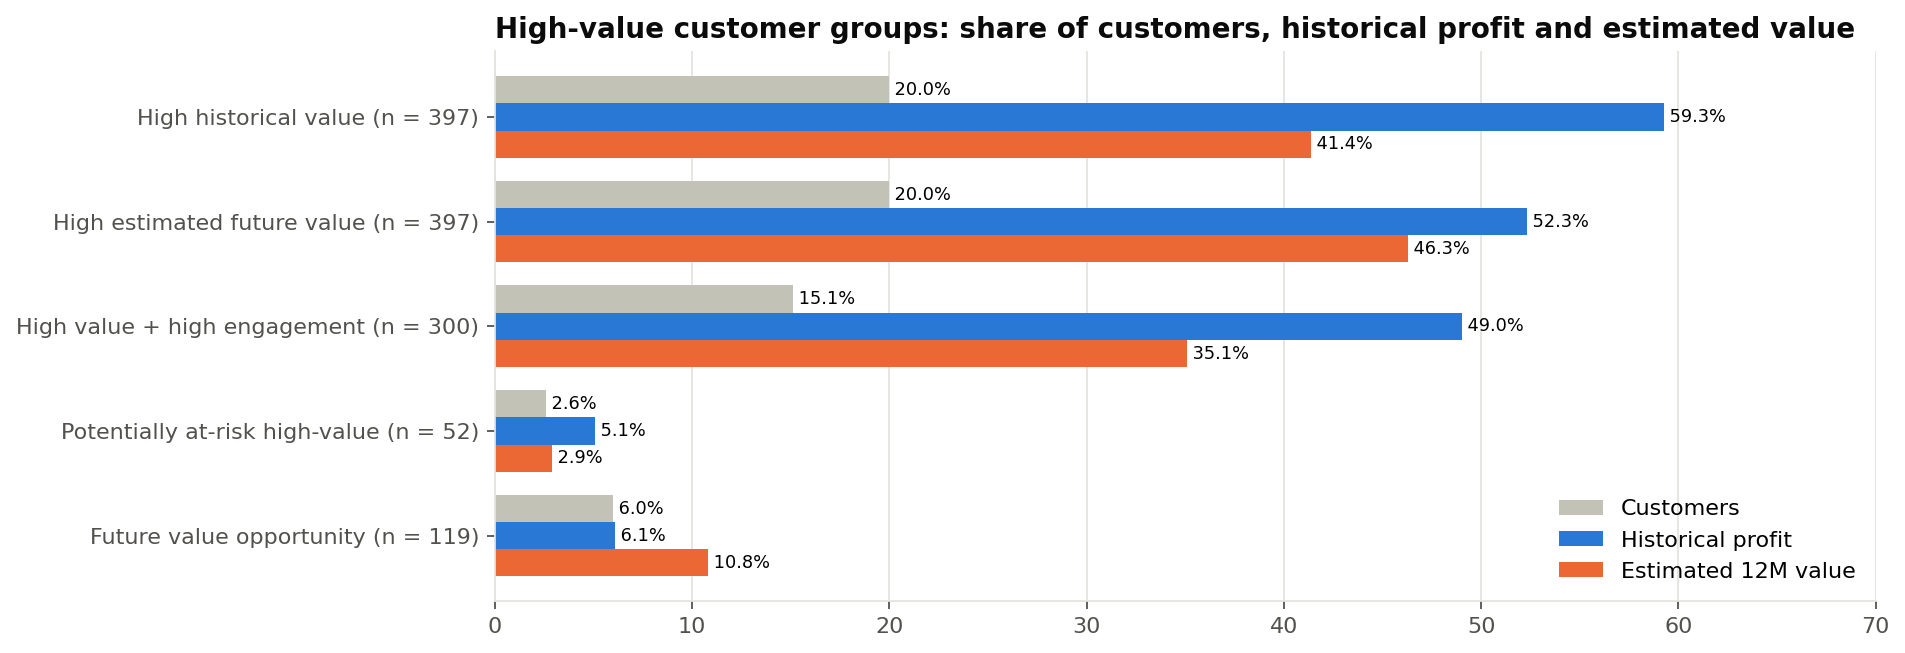

In [40]:
Image(str(FIG / "clv_high_value_groups.png"))

In [41]:
# Customer-level view (IDs only): top 10 by estimated next-12-month profit
c.sort_values("Estimated_12M_Future_Profit", ascending=False)[
    ["Customer_ID", "Historical_Profit_CLV", "Estimated_12M_Future_Profit", "Recency", "Total_Orders", "RFM_Segment", "Cluster_Label"]].head(10)

,Customer_ID,Historical_Profit_CLV,Estimated_12M_Future_Profit,Recency,Total_Orders,RFM_Segment,Cluster_Label
602,CUST-0606,"22,633.930","16,434.619",25,22,Champions,"High-Value, Active"
1219,CUST-1230,"22,982.500","16,182.626",13,12,Champions,"High-Value, Active"
1513,CUST-1527,"30,051.200","16,068.652",29,28,Champions,"High-Value, Active"
446,CUST-0450,"9,980.410","15,984.351",16,12,Champions,"High-Value, Active"
807,CUST-0814,"23,161.990","15,942.141",23,18,Champions,"High-Value, Active"
1831,CUST-1846,"43,852.540","15,729.683",36,26,Champions,"High-Value, Active"
539,CUST-0543,"40,075.770","15,593.222",130,22,Loyal Customers,"High-Value, Active"
1217,CUST-1228,"14,426.630","15,569.717",75,14,Champions,"High-Value, Active"
565,CUST-0569,"36,394.120","15,565.281",29,23,Champions,"High-Value, Active"
909,CUST-0916,"35,046.810","15,550.159",21,26,Champions,"High-Value, Active"


- **High historical value:** 397 customers (top 20%) hold 59.3% of historical profit. 300 of them are also frequent and recent.
- **Potentially at-risk high-value:** 52 customers have not bought for 180+ days. They are **not** labelled churned, because many such customers return.
- **Future value opportunity:** 119 customers are in the top 20% of estimated value without being in the top 20% of historical value.

## 14. Business Interpretation

In [42]:
R['insights']

,Insight Area,Observation,Evidence,Business Interpretation
0,High-Value Customers,Top 20% of customers generated 59.3% of historical profit,397 customers; Gini (profit) 0.56; mean/median profit ratio 1.82; skewness 2.61,"Customer value is concentrated: averages overstate the typical customer, so medians and percentiles are reported alongside means."
1,High-Value Customers,52 high-value customers have not bought for >= 180 days,They hold 5.1% of historical profit; median recency 228 days,"Potentially at-risk, not churned: at the 2025 cutoff 56% of customers inactive >= 180 days bought again within 12 months."
2,RFM Segments,"Champions have the highest average estimated 12-month value (₹8,442), close to their historical annual rate (₹8,650)",334 customers = 50.8% of historical profit and 38.1% of estimated 12-month value,The segment that generated most past value is also estimated to generate the most near-term value. Its share is lower on the estimate partly because the mod...
3,RFM Segments,Can't Lose Them: estimated 12-month value is 0.72x their historical annual profit rate - the lowest ratio of any segment,"79 customers; average historical profit ₹11,046; estimated ₹3,871 vs annual rate ₹5,411; average recency 228 days",Historical value alone would overstate what this group is estimated to contribute next year.
4,ML Clusters,Clusters 0 and 2 hold 76.9% of estimated 12-month value,"Cluster 0 (High-Value, Active): 18.3% of customers, 52.9% of historical profit, 40.0% of estimated value; Cluster 2 (Mid-Value, Lapsing): 38.0% of customers...","Cluster 0 has by far the highest value per customer (₹8,128 estimated); the lapsing mid-value cluster matters because of its size."
5,ML Clusters,"Cluster 1 (Low-Value, Active) has the highest estimated-to-historical ratio (1.68x)","Average estimated 12-month value ₹2,621 vs historical annual rate ₹1,565; average tenure 14 months","Recently active, low-value customers are estimated to be worth more next year than their short history shows - partly model shrinkage toward the average, so..."
6,Customer Tenure,Longer-tenure customers have higher historical profit (Spearman 0.36),"Median profit: tenure < 1 year ₹1,677, 1-2 years ₹4,068, >= 2 years ₹5,564; 38.7% of customers have left-censored tenure","Part of this is exposure (more time to buy), so tenure is not by itself evidence of loyalty."
7,Customer Tenure,210 single-purchase customers (10.6%) hold 1.4% of profit,"Median profit ₹735 vs ₹4,590 for repeat purchasers",Most value comes from repeat purchasing; a second purchase is the key step.
8,Profitability,Historical profit margin 23.3% overall,Historical profit ₹1.40 Cr on revenue ₹6.01 Cr; 32 customers have negative total profit,Profit CLV is the more economically meaningful measure; revenue CLV is kept for comparison.
9,Future Value,"Out-of-time test (2024 features -> 2025 profit): R² 0.27, MAE ₹2,793",Top 20% predicted captured 41.5% of actual 2025 profit; predicted/actual total 0.90; Spearman 0.49,Useful for ranking customers by expected value; individual rupee estimates are approximate and totals are conservative when activity grows.


In [43]:
R['questions']

,Question,Answer
0,What is the current/historical value of each customer?,"Stored per customer in customer_value_history.csv. Across 1,984 customers: historical revenue ₹6.01 Cr, historical profit ₹1.40 Cr; median profit per custom..."
1,Which customers generate the highest value?,The top 20% of customers by historical profit (397) generated 59.3% of all profit; the top 10% generated 41.0%. By RFM segment the top 20% are: Champions 72...
2,How does customer value differ across ML clusters?,"Average historical profit ranges from ₹1,617 (Cluster 3: Low-Value, Inactive) to ₹20,360 (Cluster 0: High-Value, Active), which holds 52.9% of historical pr..."
3,How does customer value differ across RFM segments?,"Highest average historical profit: Champions (₹21,316); lowest: About to Sleep (₹1,295)."
4,What factors are associated with higher customer value?,"Historical profit = orders x AOV x margin; the number of orders accounts for 62% of the variance in log profit, AOV 39%, margin -1% (margins differ little b..."
5,Which customers have high historical value?,397 customers (historical profit >= P80); 300 of them are also frequent and recent; 52 have not bought for >= 180 days.
6,Which customers may represent future value opportunities?,119 customers are in the top 20% of estimated 12-month value without being in the top 20% of historical value (flag Future_Value_Opportunity). The estimate ...
7,How can CLV support retention and marketing decisions?,Historical profit CLV identifies whom the business depends on today; the estimated 12-month value and the at-risk flag show where value may be lost or gaine...


- **How to read an estimate:** *the model estimates an expected next-12-month profit of approximately ₹X under the defined assumptions and prediction period.*
- **What an estimate is not:** a statement of what a customer will generate.
- **Where recommendations come later:** turning these numbers into actions is a later step.

## 15. CLV Limitations

In [44]:
R['assumptions']

,Assumption,Detail
0,Revenue rule,"Only Delivered lines count as revenue, cost and profit (Step 3 rule); Returned/Cancelled = 0."
1,Customer population,"1,984 customers with >= 1 Delivered order; the 16 customers with no Delivered order have no value to measure (same population as Step 5)."
2,Reference date,"2026-01-01 (latest order date + 1 day, Step 5)."
3,Historical CLV,"Observed 2023-2025 totals. Not a forecast; tenure is left-censored for customers who existed before 2023, so their historical value is a minimum."
4,Future-value target,Future_Profit_12M: Delivered profit in the 12 months after a cutoff.
5,Feature window,12 months before the cutoff (same length at every cutoff so the training and test features are comparable).
6,Tenure feature,Capped at 365 days because the training cutoff only has 12 months of history.
7,Model population,Customers with >= 1 Delivered order in the 12 months before the cutoff.
8,Model features,"8 features after removing exact identities and VIF > 5: Recency_Days, Frequency, AOV, Profit_Margin, Avg_Discount, Categories, Tenure_Days_Capped, Return_Rate."
9,Customers outside the model population,"Given the observed average next-12-month profit of the equivalent group at the 2025 cutoff (₹830, n = 307); a group-level estimate, not customer-specific."


1. **Synthetic data:** patterns come from the Step 2 generator.
2. **Modest per-customer accuracy** (R² 0.27): use the estimates for ranking and prioritising.
3. **Non-stationary activity** and **only one hold-out year**.
4. **Left-censored tenure** for customers who existed before 2023.
5. **No churn label:** "potentially at-risk" is a documented rule, not observed churn.
6. **Group-level estimate** for customers with no order in the last 12 months.
7. **The 3-year value is illustrative,** undiscounted and not validated.
8. **Feature importance shows association,** not causation.

## 16. CLV Summary

In [45]:
m = R["evaluation"]["metrics"]
summary = pd.DataFrame([
    ("Customers", f"{len(c):,}"),
    ("Historical revenue CLV (total)", clv.inr(c["Historical_Revenue_CLV"].sum())),
    ("Historical profit CLV (total)", clv.inr(c["Historical_Profit_CLV"].sum())),
    ("Median historical profit per customer", clv.inr(c["Historical_Profit_CLV"].median())),
    ("Selected model", R["trained"]["chosen"]),
    ("Out-of-time R² / MAE / RMSE", f"{m['R2']:.3f} / {clv.inr(m['MAE'])} / {clv.inr(m['RMSE'])}"),
    ("Estimated next-12-month profit (all customers, total)", clv.inr(c["Estimated_12M_Future_Profit"].sum())),
    ("Illustrative 3-year value (total, not validated)", clv.inr(c["Illustrative_3Y_Value"].sum())),
    ("Validation checks passed", f"{int(R['validation']['Pass'].sum())}/{len(R['validation'])}"),
], columns=["Measure", "Value"])
summary

,Measure,Value
0,Customers,"1,984"
1,Historical revenue CLV (total),₹6.01 Cr
2,Historical profit CLV (total),₹1.40 Cr
3,Median historical profit per customer,"₹3,893"
4,Selected model,Random forest
5,Out-of-time R² / MAE / RMSE,"0.270 / ₹2,793 / ₹4,269"
6,"Estimated next-12-month profit (all customers, total)",₹73.97 L
7,"Illustrative 3-year value (total, not validated)",₹1.88 Cr
8,Validation checks passed,18/18


In [46]:
for p in sorted(set(R["saved"]) | set(R["figures"]) | {R["report"]}):
    print(p.relative_to(ROOT))

data/processed/clv_modeling_dataset.csv
data/processed/customer_clv.csv
data/processed/customer_value_history.csv
models/clv_model.pkl
models/clv_model_metadata.json
models/clv_preprocessor.pkl
outputs/figures/clv_actual_vs_predicted.png
outputs/figures/clv_by_ml_cluster.png
outputs/figures/clv_by_rfm_segment.png
outputs/figures/clv_distribution.png
outputs/figures/clv_feature_importance.png
outputs/figures/clv_high_value_groups.png
outputs/figures/clv_inactivity_threshold.png
outputs/figures/clv_model_comparison.png
outputs/figures/clv_revenue_vs_profit.png
outputs/figures/clv_value_concentration.png
outputs/figures/customer_tenure_vs_value.png
outputs/figures/frequency_vs_clv.png
outputs/figures/recency_vs_clv.png
outputs/reports/clv_analysis_report.md
outputs/tables/clv_annual_repeat_rates.csv
outputs/tables/clv_assumptions.csv
outputs/tables/clv_bgnbd_evaluation.csv
outputs/tables/clv_business_insights.csv
outputs/tables/clv_business_questions.csv
outputs/tables/clv_by_ml_cluster.c